# NeuroLens — Brain Tumor MRI Classification: Baseline Comparison

This notebook compares two ways of building a 4-class brain tumor MRI classifier (glioma, meningioma, no tumor, pituitary):

| Track | Models | Runs |
|---|---|---|
| **A — Fine-tuned pretrained models** | MobileNetV2, EfficientNetB0, Xception | S1 (train new head, backbone frozen) → S2 (also fine-tune the top 20 backbone layers) |
| **B — Trained from scratch** | Custom CNN, Fibonacci-Net (Roy et al. 2025) | Custom CNN: default + hyperparameter-tuned · Fibonacci-Net: 3 learning rates · Fibonacci-Net Ablation A: 1 run |

**How to use this notebook**
- Run it on Google Colab with a GPU (*Runtime → Change runtime type → GPU*).
- Run sections **1–4** first (setup, data, preprocessing, evaluation helpers). After that, each model section can be run **on its own, one at a time**. Every model is created and trained in its own cells — no model shares training code with another.
- Every result is appended to `results.csv` on Google Drive and every trained model is saved there too. If Colab disconnects, re-run sections 1–4 and continue with the model you were on — finished models do not need to be retrained.
- The **validation** set is used for early stopping and for choosing the best configuration; the **test** set is only used to report final performance.

## 1. Setup

### 1.1 Imports

In [1]:
import os
import json
import time
import random
import hashlib
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout,
                                     BatchNormalization, GlobalAveragePooling2D, GlobalMaxPooling2D)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2, EfficientNetB0, Xception

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                             classification_report, confusion_matrix)

sns.set_style("whitegrid")
print("TensorFlow:", tf.__version__)
print("GPUs available:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### 1.2 Configuration

All training settings are defined once here so that every model is trained under the same conditions.

**`QUICK_RUN`** switches between a fast first pass and the full run used for the report:

| Setting | Quick run (`QUICK_RUN = True`) | Full run (`QUICK_RUN = False`) | Used for |
|---|---|---|---|
| `EPOCHS_S1` | 5 | 15 | S1 — training the new head on a frozen backbone |
| `EPOCHS_FT` | 3 | 10 | S2 — fine-tuning (small learning rate, few epochs needed) |
| `EPOCHS_SCRATCH` | 15 | 40 | Custom CNN and Fibonacci-Net (trained from random weights, need more epochs) |
| `TUNER_TRIALS` / `TUNER_EPOCHS` | 3 / 5 | 10 / 15 | KerasTuner search for the custom CNN |

Other settings: `IMG_SIZE` 224 × 224 for all models, `BATCH_SIZE` 32 (lower to 16 if the GPU runs out of memory), `FT_TOP_LAYERS` 20 backbone layers unfrozen in S2.

Early stopping (on validation loss) ends training sooner whenever the model stops improving. A quick run gives a first comparison in a fraction of the time; its numbers are lower than a full run's, so **report the full-run results** (or state clearly that the quick settings were used).

In [2]:
SEED = 42
IMG_SIZE = (224, 224)
IMG_SHAPE = (224, 224, 3)
BATCH_SIZE = 32
VAL_FRACTION = 0.15
FT_TOP_LAYERS = 20

QUICK_RUN = True        # True = fast first pass · False = full training for the final report

if QUICK_RUN:
    EPOCHS_S1, EPOCHS_FT, EPOCHS_SCRATCH = 5, 3, 15
    TUNER_TRIALS, TUNER_EPOCHS = 3, 5
else:
    EPOCHS_S1, EPOCHS_FT, EPOCHS_SCRATCH = 15, 10, 40
    TUNER_TRIALS, TUNER_EPOCHS = 10, 15
print(f"{'QUICK' if QUICK_RUN else 'FULL'} run: S1 {EPOCHS_S1} · S2 {EPOCHS_FT} · from scratch {EPOCHS_SCRATCH} epochs · "
      f"tuner {TUNER_TRIALS} trials x {TUNER_EPOCHS} epochs")

def set_seeds(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seeds()

QUICK run: S1 5 · S2 3 · from scratch 15 epochs · tuner 3 trials x 5 epochs


### 1.3 Google Drive (results and saved models)

Trained models and the results table are saved to Google Drive so they survive a Colab disconnect.

In [3]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT_DIR = "/content/drive/MyDrive/NeuroLens"
except ImportError:          # running outside Colab
    OUTPUT_DIR = "outputs"

MODEL_DIR = os.path.join(OUTPUT_DIR, "models")
RESULTS_CSV = os.path.join(OUTPUT_DIR, "results.csv")
os.makedirs(MODEL_DIR, exist_ok=True)
print("Saving models to:", MODEL_DIR)
print("Results table:", RESULTS_CSV)

Mounted at /content/drive
Saving models to: /content/drive/MyDrive/NeuroLens/models
Results table: /content/drive/MyDrive/NeuroLens/results.csv


## 2. Data

### 2.1 Download the dataset (version 1)

The Kaggle *Brain Tumor MRI Dataset* (Nickparvar) combines the Figshare, SARTAJ and Br35H collections. **Version 1** (the original release) is used on purpose: its classes are **imbalanced**, which reflects real clinical data, where tumor types are rarely equally common. (Version 2 of the dataset was artificially balanced by the publisher.) Handling this imbalance is part of the preprocessing in Section 3.

In [4]:
import kagglehub

base_path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset/versions/1")

# Locate the folder that contains Training/ and Testing/
DATASET_PATH = base_path
for root, dirs, files in os.walk(base_path):
    if "Training" in dirs and "Testing" in dirs:
        DATASET_PATH = root
        break

TRAIN_DIR = os.path.join(DATASET_PATH, "Training")
TEST_DIR = os.path.join(DATASET_PATH, "Testing")
print("Dataset path:", DATASET_PATH)
print("Training classes:", sorted(os.listdir(TRAIN_DIR)))
print("Testing classes:", sorted(os.listdir(TEST_DIR)))

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Dataset path: /kaggle/input/brain-tumor-mri-dataset
Training classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Testing classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


### 2.2 Load image paths and labels

Each class is a subfolder. The images are listed in a table (one row per image) with their class label and whether they come from the Training or Testing folder. The Testing folder is kept untouched as the final test set.

In [5]:
CLASS_NAMES = sorted(d for d in os.listdir(TRAIN_DIR) if os.path.isdir(os.path.join(TRAIN_DIR, d)))
NUM_CLASSES = len(CLASS_NAMES)
CLASS_INDICES = {name: i for i, name in enumerate(CLASS_NAMES)}

def load_split(split_dir, split_name):
    rows = []
    for label in CLASS_NAMES:
        folder = os.path.join(split_dir, label)
        for fname in sorted(os.listdir(folder)):
            if fname.lower().endswith((".png", ".jpg", ".jpeg")):
                rows.append({"image_path": os.path.join(folder, fname), "label": label, "split": split_name})
    return pd.DataFrame(rows)

train_full_df = load_split(TRAIN_DIR, "Training")
test_df = load_split(TEST_DIR, "Testing")
all_df = pd.concat([train_full_df, test_df], ignore_index=True)

print("Classes:", CLASS_INDICES)
print(f"Training images: {len(train_full_df)} | Testing images: {len(test_df)}")
all_df.head()

Classes: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Training images: 5712 | Testing images: 1311


,image_path,label,split
0,/kaggle/input/brain-tumor-mri-dataset/Training...,glioma,Training
1,/kaggle/input/brain-tumor-mri-dataset/Training...,glioma,Training
2,/kaggle/input/brain-tumor-mri-dataset/Training...,glioma,Training
3,/kaggle/input/brain-tumor-mri-dataset/Training...,glioma,Training
4,/kaggle/input/brain-tumor-mri-dataset/Training...,glioma,Training


### 2.3 Exploratory data analysis — class distribution

The class counts show how imbalanced the dataset is. Glioma, the clinically most serious class, is among the smaller classes.

In [6]:
pd.crosstab(all_df["label"], all_df["split"], margins=True)

split,Testing,Training,All
label,,,
glioma,300,1321,1621
meningioma,306,1339,1645
notumor,405,1595,2000
pituitary,300,1457,1757
All,1311,5712,7023


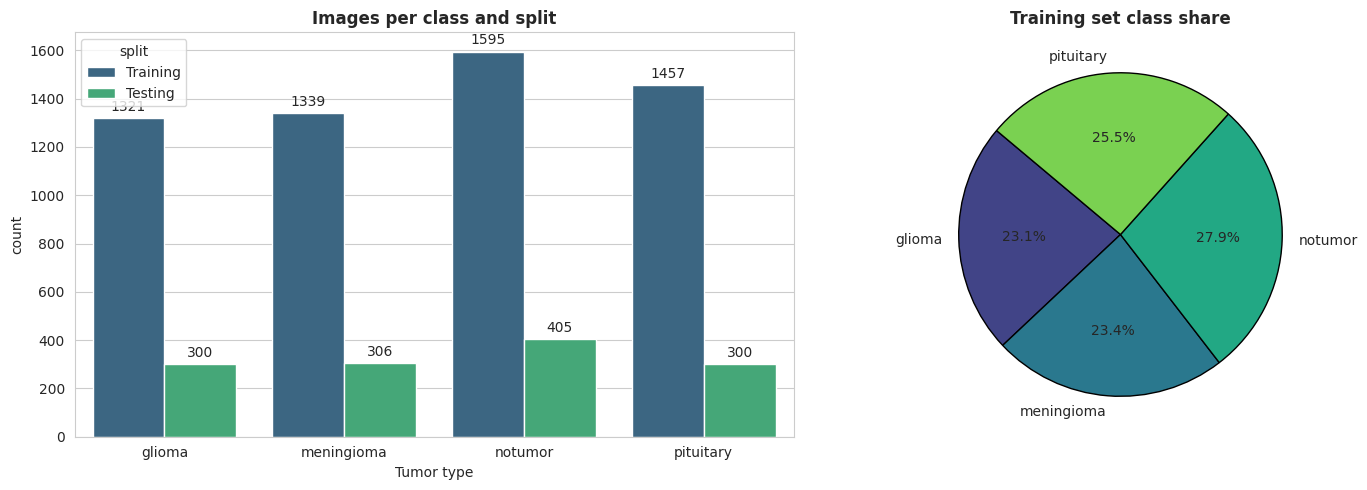

Imbalance ratio (largest / smallest training class): 1.21


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.countplot(data=all_df, x="label", hue="split", order=CLASS_NAMES, palette="viridis", ax=axes[0])
axes[0].set_title("Images per class and split", fontweight="bold")
axes[0].set_xlabel("Tumor type")
for p in axes[0].patches:
    if p.get_height() > 0:
        axes[0].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                         ha="center", va="bottom", xytext=(0, 3), textcoords="offset points")

counts = train_full_df["label"].value_counts().reindex(CLASS_NAMES)
axes[1].pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=140,
            colors=sns.color_palette("viridis", NUM_CLASSES), wedgeprops={"edgecolor": "black"})
axes[1].set_title("Training set class share", fontweight="bold")

plt.tight_layout()
plt.show()

print(f"Imbalance ratio (largest / smallest training class): {counts.max() / counts.min():.2f}")

### 2.4 Sample images and image sizes

The images come from three different collections, so their sizes vary. All images are resized to 224 × 224 during preprocessing.

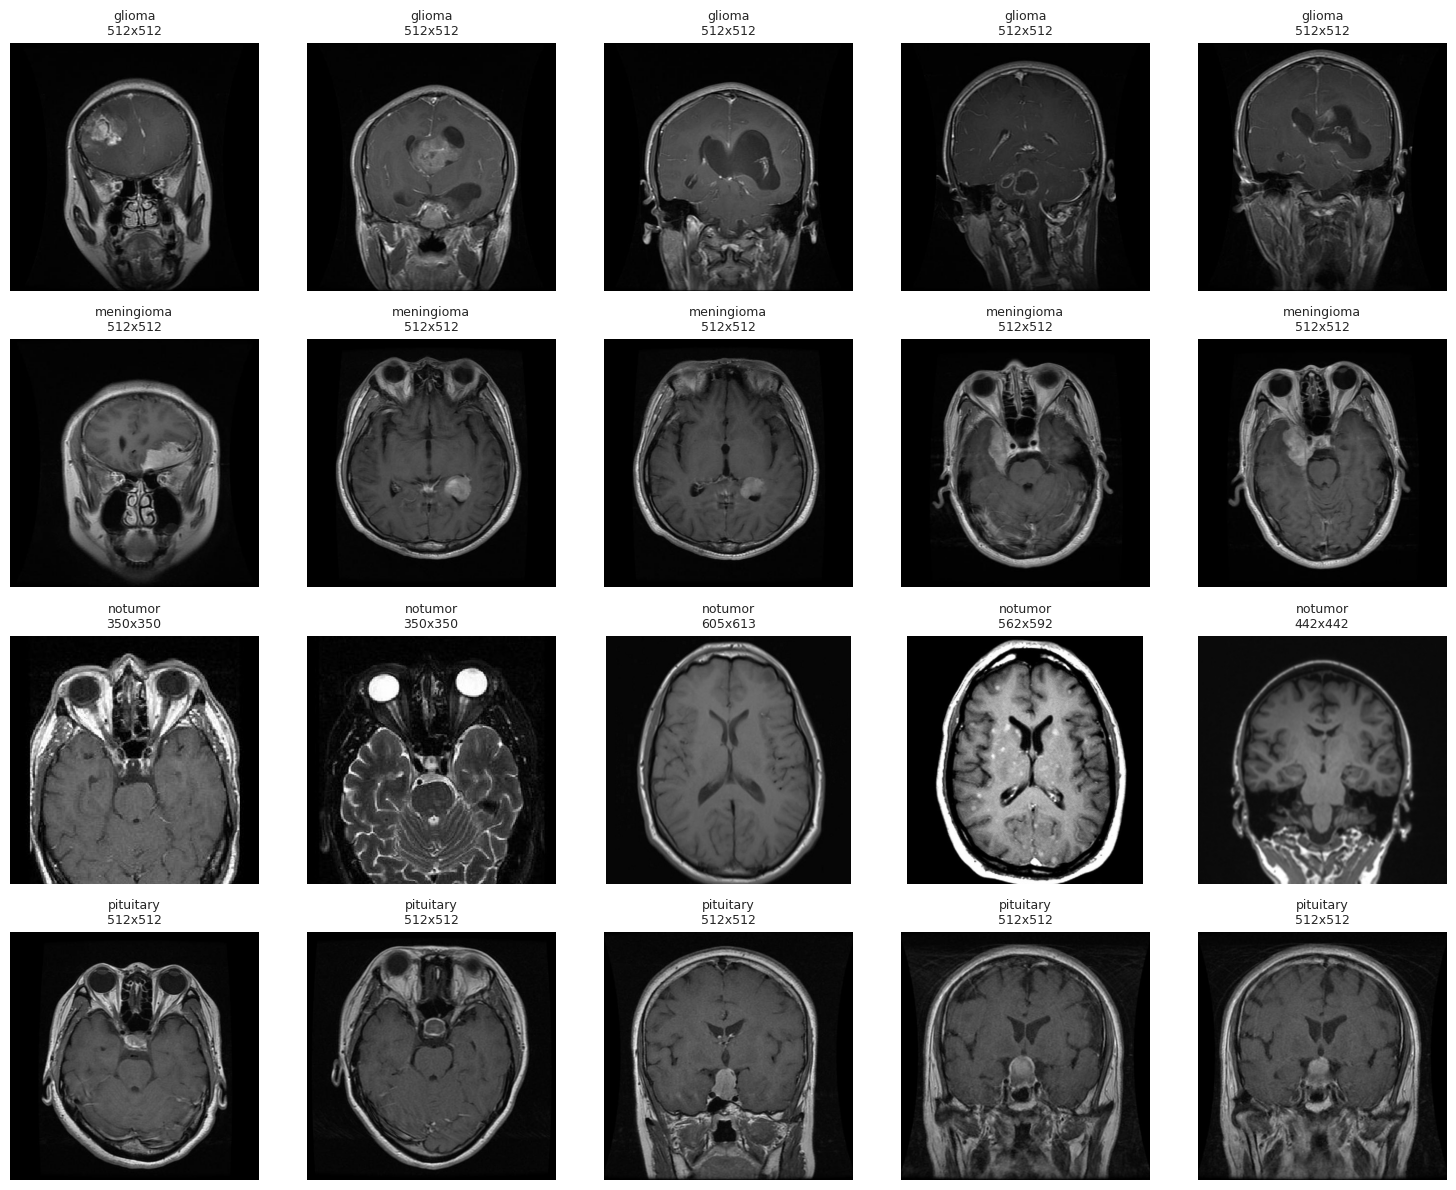

Image sizes (sample of 500):
      width  height
min   150.0   168.0
mean  442.0   446.0
max   785.0   848.0


In [8]:
num_images = 5
plt.figure(figsize=(15, 12))
for i, label in enumerate(CLASS_NAMES):
    paths = train_full_df[train_full_df["label"] == label]["image_path"].iloc[:num_images]
    for j, path in enumerate(paths):
        img = Image.open(path).convert("RGB")
        plt.subplot(NUM_CLASSES, num_images, i * num_images + j + 1)
        plt.imshow(img)
        plt.title(f"{label}\n{img.size[0]}x{img.size[1]}", fontsize=9)
        plt.axis("off")
plt.tight_layout()
plt.show()

sizes = pd.DataFrame([Image.open(p).size for p in all_df["image_path"].sample(min(500, len(all_df)), random_state=SEED)],
                     columns=["width", "height"])
print("Image sizes (sample of 500):")
print(sizes.describe().loc[["min", "mean", "max"]].round(0))

## 3. Preprocessing

### 3.1 Duplicate and leakage check

Version 1 merges three public collections, so some images appear more than once — including identical images in both Training and Testing. If a test image is also in the training data, test accuracy is inflated. Exact duplicates are found by hashing the file contents (MD5):
- training images that also appear in Testing are **removed from training** (the test set stays as published);
- repeated images inside Training are kept **only once**.

In [9]:
def file_md5(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

train_full_df["md5"] = train_full_df["image_path"].map(file_md5)
test_df["md5"] = test_df["image_path"].map(file_md5)

leak_mask = train_full_df["md5"].isin(set(test_df["md5"]))
conflicts = pd.concat([train_full_df, test_df]).groupby("md5")["label"].nunique()

print(f"Training images also in Testing (leakage): {leak_mask.sum()}")
print(f"Duplicates inside Training:                {train_full_df['md5'].duplicated().sum()}")
print(f"Duplicates inside Testing:                 {test_df['md5'].duplicated().sum()}")
print(f"Identical images with different labels:    {(conflicts > 1).sum()}")

train_clean_df = (train_full_df[~leak_mask]
                  .drop_duplicates(subset="md5")
                  .reset_index(drop=True))
print(f"\nTraining images: {len(train_full_df)} -> {len(train_clean_df)} after cleaning")

Training images also in Testing (leakage): 134
Duplicates inside Training:                191
Duplicates inside Testing:                 27
Identical images with different labels:    0

Training images: 5712 -> 5442 after cleaning


### 3.2 Train / validation / test split

- **Validation (15%)** is carved out of the cleaned Training data, stratified so every class keeps its proportion. It is used for early stopping and for choosing between configurations (S1 vs. S2, learning rates, default vs. tuned CNN).
- **Test** is the publisher's Testing folder, used only for the final results.

In [10]:
train_df, val_df = train_test_split(
    train_clean_df, test_size=VAL_FRACTION, stratify=train_clean_df["label"], random_state=SEED
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

split_counts = pd.DataFrame({
    "train": train_df["label"].value_counts(),
    "validation": val_df["label"].value_counts(),
    "test": test_df["label"].value_counts(),
}).reindex(CLASS_NAMES)
split_counts.loc["TOTAL"] = split_counts.sum()
split_counts

,train,validation,test
label,,,
glioma,1123,198,300
meningioma,1131,200,306
notumor,1147,203,405
pituitary,1224,216,300
TOTAL,4625,817,1311


### 3.3 Handling class imbalance — augmentation-based oversampling

Real clinical datasets are rarely balanced, so the imbalance is handled in preprocessing rather than by choosing a balanced dataset.

**Method:** in the **training split only**, images from the smaller classes are repeated until every class has as many images as the largest class. The repeats are **not identical copies**: data augmentation (Section 3.4) is applied randomly every time an image is loaded, so each repeat is a different rotated, shifted, zoomed, flipped or brightened version of the original.

**Why only after the split:** oversampling before splitting would place copies of the same image in both training and validation/test, which inflates the scores. The validation and test sets are never oversampled or augmented.

            before oversampling  after oversampling
label                                              
glioma                     1123                1224
meningioma                 1131                1224
notumor                    1147                1224
pituitary                  1224                1224


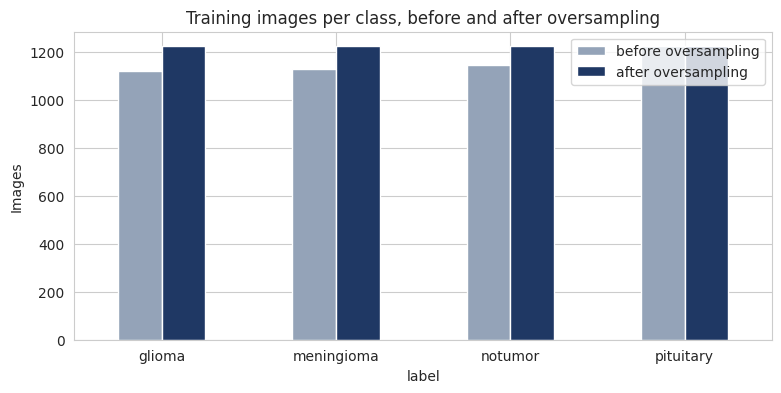

In [11]:
def oversample(df, seed=SEED):
    target = df["label"].value_counts().max()
    parts = []
    for label, group in df.groupby("label"):
        extra = group.sample(n=target - len(group), replace=True, random_state=seed) if len(group) < target else group.iloc[:0]
        parts.append(pd.concat([group, extra]))
    return pd.concat(parts).sample(frac=1, random_state=seed).reset_index(drop=True)

train_balanced_df = oversample(train_df)

balance = pd.DataFrame({
    "before oversampling": train_df["label"].value_counts(),
    "after oversampling": train_balanced_df["label"].value_counts(),
}).reindex(CLASS_NAMES)
print(balance)

balance.plot(kind="bar", figsize=(9, 4), color=["#94a3b8", "#1f3864"], rot=0,
             title="Training images per class, before and after oversampling")
plt.ylabel("Images")
plt.show()

### 3.4 Data augmentation and image generators

Three generators feed images to every model:

| Generator | Source | Preprocessing |
|---|---|---|
| `train_gen` | oversampled training split | resize to 224×224, scale pixels to [0, 1], **random augmentation**: rotation ±10°, shift ±5%, zoom ±10%, horizontal flip, brightness 0.9–1.1 |
| `val_gen` | validation split | resize, scale to [0, 1] — no augmentation |
| `test_gen` | test split | resize, scale to [0, 1] — no augmentation |

The augmentations are mild on purpose: MRI slices should still look anatomically realistic. Vertical flips are not used because brain scans have a consistent top-bottom orientation. Validation and test are not shuffled, so predictions line up with their labels.

In [12]:
def make_generators(batch_size=BATCH_SIZE):
    train_aug = ImageDataGenerator(
        rescale=1.0 / 255,
        rotation_range=10,
        width_shift_range=0.05,
        height_shift_range=0.05,
        zoom_range=0.1,
        horizontal_flip=True,
        brightness_range=[0.9, 1.1],
        fill_mode="constant",
        cval=0,
    )
    plain = ImageDataGenerator(rescale=1.0 / 255)
    common = dict(x_col="image_path", y_col="label", classes=CLASS_NAMES, target_size=IMG_SIZE,
                  class_mode="categorical", color_mode="rgb", batch_size=batch_size)
    train = train_aug.flow_from_dataframe(train_balanced_df, shuffle=True, seed=SEED, **common)
    val = plain.flow_from_dataframe(val_df, shuffle=False, **common)
    test = plain.flow_from_dataframe(test_df, shuffle=False, **common)
    return train, val, test

train_gen, val_gen, test_gen = make_generators()
print("Class indices:", train_gen.class_indices)

Found 4896 validated image filenames belonging to 4 classes.
Found 817 validated image filenames belonging to 4 classes.
Found 1311 validated image filenames belonging to 4 classes.
Class indices: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


### 3.5 Check the augmentation

The first row shows one original training image; the second row shows five random augmented versions of it — this is what the oversampled repeats of minority-class images look like to the model. The last cell checks that a batch has the expected shape, pixel range and one-hot labels.

Found 5 validated image filenames belonging to 4 classes.


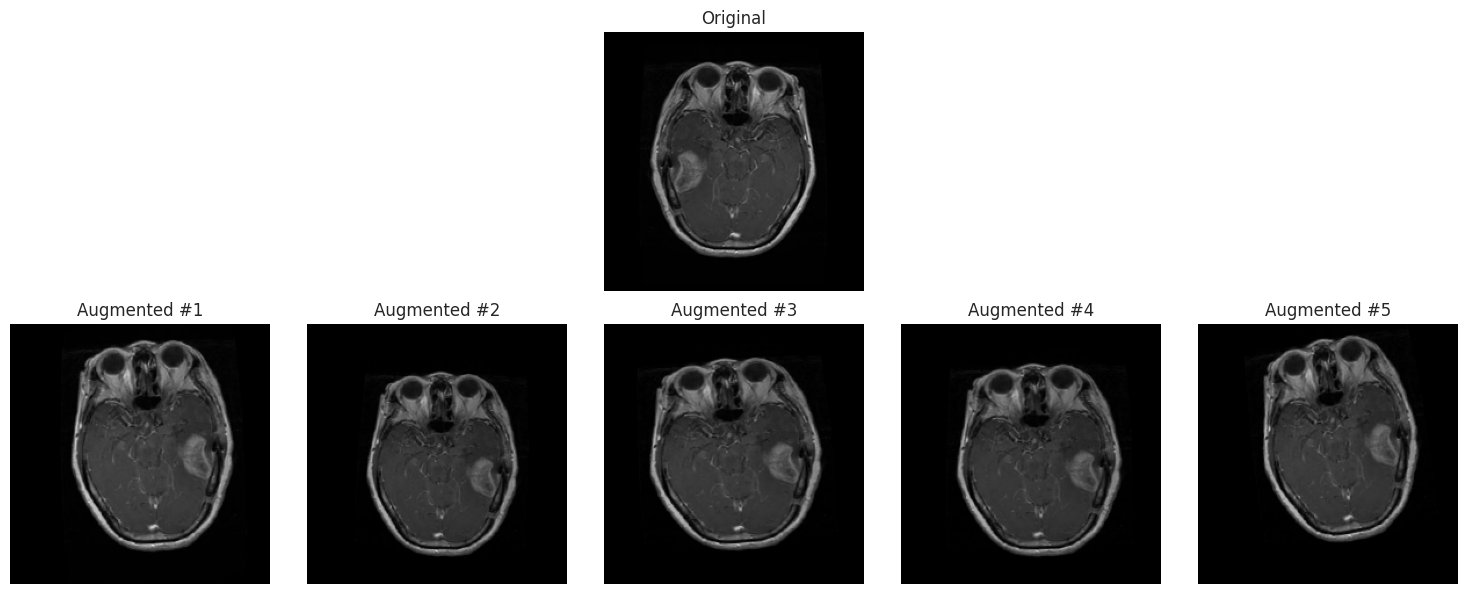

In [13]:
sample_path = train_df[train_df["label"] == train_df["label"].value_counts().idxmin()]["image_path"].iloc[0]
demo_df = pd.DataFrame({"image_path": [sample_path] * 5, "label": [CLASS_NAMES[0]] * 5})
aug_only = ImageDataGenerator(rotation_range=10, width_shift_range=0.05, height_shift_range=0.05,
                              zoom_range=0.1, horizontal_flip=True, brightness_range=[0.9, 1.1],
                              fill_mode="constant", cval=0, rescale=1.0 / 255)
demo_gen = aug_only.flow_from_dataframe(demo_df, x_col="image_path", y_col="label", classes=CLASS_NAMES,
                                        target_size=IMG_SIZE, batch_size=5, shuffle=False, seed=SEED)
aug_batch, _ = next(demo_gen)

plt.figure(figsize=(15, 6))
plt.subplot(2, 5, 3)
plt.imshow(Image.open(sample_path).convert("RGB").resize(IMG_SIZE))
plt.title("Original")
plt.axis("off")
for i in range(5):
    plt.subplot(2, 5, 6 + i)
    plt.imshow(aug_batch[i])
    plt.title(f"Augmented #{i + 1}")
    plt.axis("off")
plt.tight_layout()
plt.show()

In [14]:
x_batch, y_batch = next(train_gen)
print("Batch shape:", x_batch.shape, "| Labels shape:", y_batch.shape,
      "| Pixel range:", round(float(x_batch.min()), 3), "to", round(float(x_batch.max()), 3))
train_gen.reset()

Batch shape: (32, 224, 224, 3) | Labels shape: (32, 4) | Pixel range: 0.0 to 1.0


## 4. Evaluation helpers

These helper functions are used **after** each model has been trained, so that every model is measured and recorded in exactly the same way. (Model creation and training are written out separately for every model in Sections 5 and 6.)

| Function | What it does |
|---|---|
| `plot_training` | plots training vs. validation accuracy and loss for one training run |
| `predict_labels` | runs a model on a generator and returns the true and predicted classes |
| `cpu_latency_ms` | measures how long the model takes to classify one image on a CPU |
| `evaluate_and_record` | evaluates a model on the validation and test sets, saves the model to Drive and adds one row to `results.csv` |
| `load_results`, `show_results` | read `results.csv` and show the rows for one model |

Columns recorded in `results.csv`:

| Column | Meaning |
|---|---|
| `val_macro_f1` | used to choose the best configuration (S1 vs. S2, learning rate, default vs. tuned) |
| `test_accuracy`, `test_macro_f1` | final performance on the test set |
| `recall_<class>` | test recall for each class — `recall_glioma` matters most clinically |
| `params_M`, `size_MB` | model size |
| `cpu_latency_ms` | time to classify one image on a CPU (relevant for deployment) |

In [15]:
def plot_training(history, title):
    plt.figure(figsize=(12, 4))
    for i, metric in enumerate(["accuracy", "loss"]):
        plt.subplot(1, 2, i + 1)
        plt.plot(history.history[metric], label=f"train {metric}")
        plt.plot(history.history[f"val_{metric}"], label=f"validation {metric}")
        plt.title(f"{title} — {metric}")
        plt.xlabel("epoch")
        plt.legend()
    plt.tight_layout()
    plt.show()


def predict_labels(model, gen):
    gen.reset()
    probs = model.predict(gen, verbose=0)
    return gen.classes, np.argmax(probs, axis=1)


def cpu_latency_ms(model, runs=30):
    """Median time to classify one image on the CPU (copies the model to the CPU first)."""
    with tf.device("/CPU:0"):
        cpu_model = tf.keras.models.clone_model(model)
        cpu_model.set_weights(model.get_weights())
        x = tf.random.uniform((1,) + IMG_SHAPE)
        for _ in range(3):
            cpu_model(x, training=False)
        times = []
        for _ in range(runs):
            start = time.perf_counter()
            cpu_model(x, training=False)
            times.append((time.perf_counter() - start) * 1000)
    return float(np.median(times))


def load_results():
    return pd.read_csv(RESULTS_CSV) if os.path.exists(RESULTS_CSV) else pd.DataFrame()


def evaluate_and_record(model, run_name, model_name, track, config, history=None, train_time=None, group="main"):
    """Evaluates on validation + test, saves the model and adds a row to results.csv."""
    model_path = os.path.join(MODEL_DIR, run_name.replace(" | ", "_").replace(" ", "_") + ".keras")
    model.save(model_path)

    y_val, p_val = predict_labels(model, val_gen)
    y_test, p_test = predict_labels(model, test_gen)
    per_class_recall = recall_score(y_test, p_test, labels=range(NUM_CLASSES), average=None, zero_division=0)

    row = {
        "run": run_name, "model": model_name, "track": track, "config": config, "group": group,
        "val_accuracy": accuracy_score(y_val, p_val),
        "val_macro_f1": f1_score(y_val, p_val, average="macro"),
        "test_accuracy": accuracy_score(y_test, p_test),
        "test_macro_f1": f1_score(y_test, p_test, average="macro"),
        **{f"recall_{c}": r for c, r in zip(CLASS_NAMES, per_class_recall)},
        "params_M": round(model.count_params() / 1e6, 3),
        "size_MB": round(os.path.getsize(model_path) / 1e6, 1),
        "cpu_latency_ms": round(cpu_latency_ms(model), 1),
        "epochs": len(history.history["loss"]) if history is not None else None,
        "train_min": round(train_time / 60, 1) if train_time else None,
        "confusion_matrix": json.dumps(confusion_matrix(y_test, p_test, labels=range(NUM_CLASSES)).tolist()),
        "model_path": model_path,
    }

    results = load_results()
    if len(results):
        results = results[results["run"] != run_name]      # re-running a step replaces its old row
    results = pd.concat([results, pd.DataFrame([row])], ignore_index=True)
    results.to_csv(RESULTS_CSV, index=False)

    print(classification_report(y_test, p_test, target_names=CLASS_NAMES, digits=3))
    summary = {k: row[k] for k in ["val_macro_f1", "test_accuracy", "test_macro_f1", "recall_glioma",
                                    "params_M", "cpu_latency_ms"] if k in row}
    print(f"Recorded '{run_name}':", {k: round(v, 4) if isinstance(v, float) else v for k, v in summary.items()})
    return row


def show_results(model_name):
    results = load_results()
    cols = ["run", "val_macro_f1", "test_accuracy", "test_macro_f1", "recall_glioma", "params_M", "cpu_latency_ms", "epochs"]
    return results[results["model"] == model_name][[c for c in cols if c in results.columns]]

## 5. Track A — Fine-tuning pretrained models

Each pretrained model is used in the same two stages:

| Stage | What is trained | What stays frozen | Learning rate |
|---|---|---|---|
| **S1 — Feature extraction** | only the new classification head | the whole pretrained backbone | 1e-3 |
| **S2 — Fine-tuning** | the head **and** the top 20 backbone layers | the rest of the backbone, and all BatchNorm layers | 1e-5 |

S2 continues from the model trained in S1: the head has already learned sensible weights, so the pretrained layers can then be adjusted gently with a very small learning rate without being damaged. BatchNormalization layers stay frozen, because updating their statistics with small batches would disturb the pretrained features.

**The new classification head** (the same for all three models): global pooling → Dense(256, ReLU) → Dropout(0.4) → Dense(4, softmax).

**Input scaling.** The generators give pixels in the range [0, 1], but each backbone expects the range it was trained with on ImageNet. A `Rescaling` layer at the start of the model converts it:

| Model | Expected input | Rescaling layer |
|---|---|---|
| MobileNetV2 | [-1, 1] | `Rescaling(2.0, offset=-1.0)` |
| EfficientNetB0 | [0, 255] | `Rescaling(255.0)` (EfficientNet normalises internally) |
| Xception | [-1, 1] | `Rescaling(2.0, offset=-1.0)` |

### 5.1 MobileNetV2

A lightweight pretrained network (≈2.3M backbone parameters) built from depth-wise separable convolutions and inverted residual blocks. It is the pretrained model closest in size to Fibonacci-Net, so it is the most direct efficiency comparison.

#### Step 1 — Load the pretrained backbone

`include_top=False` removes the original ImageNet classifier (1,000 classes); we keep only the feature-extracting layers. `trainable = False` freezes all of them for S1.

In [16]:
mobilenet_base = MobileNetV2(input_shape=IMG_SHAPE, include_top=False, weights="imagenet")
mobilenet_base.trainable = False

print("Backbone:", mobilenet_base.name)
print("Number of backbone layers:", len(mobilenet_base.layers))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Backbone: mobilenetv2_1.00_224
Number of backbone layers: 154


#### Step 2 — Add the input scaling and the new classification head

`training=False` keeps the backbone's BatchNorm layers in inference mode, also later during fine-tuning.

In [17]:
inputs = Input(shape=IMG_SHAPE)
x = layers.Rescaling(2.0, offset=-1.0)(inputs)          # [0, 1] -> [-1, 1]
x = mobilenet_base(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.4)(x)
outputs = Dense(NUM_CLASSES, activation="softmax")(x)

mobilenet_model = Model(inputs, outputs, name="mobilenetv2")
mobilenet_model.summary()

Model: "mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,586,948 (9.87 MB)

 Trainable params: 328,964 (1.25 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

#### Step 3 — S1: train the new head (backbone frozen)

Only the new head is trained, with learning rate 1e-3, for up to 15 epochs. **Early stopping** ends training when the validation loss stops improving for 4 epochs and restores the best weights; **ReduceLROnPlateau** halves the learning rate when progress stalls.

In [18]:
set_seeds()
mobilenet_model.compile(optimizer=Adam(learning_rate=1e-3), loss="categorical_crossentropy", metrics=["accuracy"])

start = time.time()
history_mobilenet_s1 = mobilenet_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_S1,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
    ],
)
mobilenet_s1_time = time.time() - start

Epoch 1/5
153/153 ━━━━━━━━━━━━━━━━━━━━ 112s 604ms/step - accuracy: 0.8037 - loss: 0.5154 - val_accuracy: 0.8776 - val_loss: 0.3217 - learning_rate: 0.0010
Epoch 2/5
153/153 ━━━━━━━━━━━━━━━━━━━━ 75s 493ms/step - accuracy: 0.8819 - loss: 0.3199 - val_accuracy: 0.8984 - val_loss: 0.2726 - learning_rate: 0.0010
Epoch 3/5
153/153 ━━━━━━━━━━━━━━━━━━━━ 75s 491ms/step - accuracy: 0.8907 - loss: 0.2898 - val_accuracy: 0.8898 - val_loss: 0.2933 - learning_rate: 0.0010
Epoch 4/5
153/153 ━━━━━━━━━━━━━━━━━━━━ 76s 495ms/step - accuracy: 0.9040 - loss: 0.2450 - val_accuracy: 0.9106 - val_loss: 0.2415 - learning_rate: 0.0010
Epoch 5/5
153/153 ━━━━━━━━━━━━━━━━━━━━ 76s 494ms/step - accuracy: 0.9163 - loss: 0.2346 - val_accuracy: 0.9106 - val_loss: 0.2324 - learning_rate: 0.0010


#### Step 4 — S1: evaluate and record

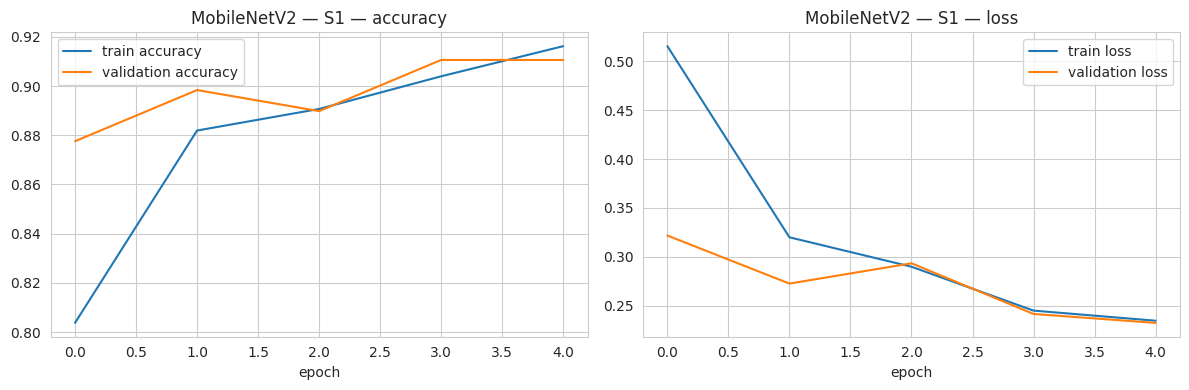

              precision    recall  f1-score   support

      glioma      0.929     0.780     0.848       300
  meningioma      0.761     0.758     0.759       306
     notumor      0.938     0.965     0.951       405
   pituitary      0.869     0.977     0.920       300

    accuracy                          0.877      1311
   macro avg      0.874     0.870     0.870      1311
weighted avg      0.879     0.877     0.876      1311

Recorded 'MobileNetV2 | S1': {'val_macro_f1': 0.9088, 'test_accuracy': 0.8772, 'test_macro_f1': 0.8696, 'recall_glioma': np.float64(0.78), 'params_M': 2.587, 'cpu_latency_ms': 189.6}


{'run': 'MobileNetV2 | S1',
 'model': 'MobileNetV2',
 'track': 'A',
 'config': 'S1',
 'group': 'main',
 'val_accuracy': 0.9106487148102815,
 'val_macro_f1': 0.9088167980927929,
 'test_accuracy': 0.8771929824561403,
 'test_macro_f1': 0.8696280735213472,
 'recall_glioma': np.float64(0.78),
 'recall_meningioma': np.float64(0.7581699346405228),
 'recall_notumor': np.float64(0.9654320987654321),
 'recall_pituitary': np.float64(0.9766666666666667),
 'params_M': 2.587,
 'size_MB': 13.6,
 'cpu_latency_ms': 189.6,
 'epochs': 5,
 'train_min': 6.9,
 'confusion_matrix': '[[234, 64, 0, 2], [12, 232, 26, 36], [5, 3, 391, 6], [1, 6, 0, 293]]',
 'model_path': '/content/drive/MyDrive/NeuroLens/models/MobileNetV2_S1.keras'}

In [19]:
plot_training(history_mobilenet_s1, "MobileNetV2 — S1")
evaluate_and_record(mobilenet_model, "MobileNetV2 | S1", "MobileNetV2", "A", "S1", history_mobilenet_s1, mobilenet_s1_time)

#### Step 5 — S2: unfreeze the top 20 backbone layers

The backbone is unlocked, then everything except the last 20 layers is frozen again. BatchNorm layers inside those 20 stay frozen. Keras counts every layer (including BatchNorm, activation and add layers), so the last 20 layers correspond roughly to the backbone's final block.

*If the Colab session restarted after S1, run the two commented lines first to reload the S1 model from Drive.*

In [20]:
# mobilenet_model = tf.keras.models.load_model(os.path.join(MODEL_DIR, "MobileNetV2_S1.keras"))
# mobilenet_base = mobilenet_model.layers[2]

mobilenet_base.trainable = True
for layer in mobilenet_base.layers[:-FT_TOP_LAYERS]:
    layer.trainable = False
for layer in mobilenet_base.layers[-FT_TOP_LAYERS:]:
    if isinstance(layer, BatchNormalization):
        layer.trainable = False

trainable_params = sum(int(np.prod(w.shape)) for w in mobilenet_model.trainable_weights)
print(f"Trainable parameters: {trainable_params:,} of {mobilenet_model.count_params():,}")

Trainable parameters: 1,523,844 of 2,586,948


#### Step 6 — S2: fine-tune

The model must be **compiled again** after changing which layers are trainable. The learning rate is very small (1e-5) so the pretrained weights are only adjusted to MRI images, not overwritten. Up to 10 epochs, early stopping patience 3.

In [21]:
set_seeds()
mobilenet_model.compile(optimizer=Adam(learning_rate=1e-5), loss="categorical_crossentropy", metrics=["accuracy"])

start = time.time()
history_mobilenet_s2 = mobilenet_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_FT,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
    ],
)
mobilenet_s2_time = time.time() - start

Epoch 1/3
153/153 ━━━━━━━━━━━━━━━━━━━━ 97s 554ms/step - accuracy: 0.9240 - loss: 0.1906 - val_accuracy: 0.9192 - val_loss: 0.2068 - learning_rate: 1.0000e-05
Epoch 2/3
153/153 ━━━━━━━━━━━━━━━━━━━━ 77s 503ms/step - accuracy: 0.9406 - loss: 0.1571 - val_accuracy: 0.9302 - val_loss: 0.1764 - learning_rate: 1.0000e-05
Epoch 3/3
153/153 ━━━━━━━━━━━━━━━━━━━━ 76s 496ms/step - accuracy: 0.9461 - loss: 0.1498 - val_accuracy: 0.9217 - val_loss: 0.1818 - learning_rate: 1.0000e-05


#### Step 7 — S2: evaluate and record

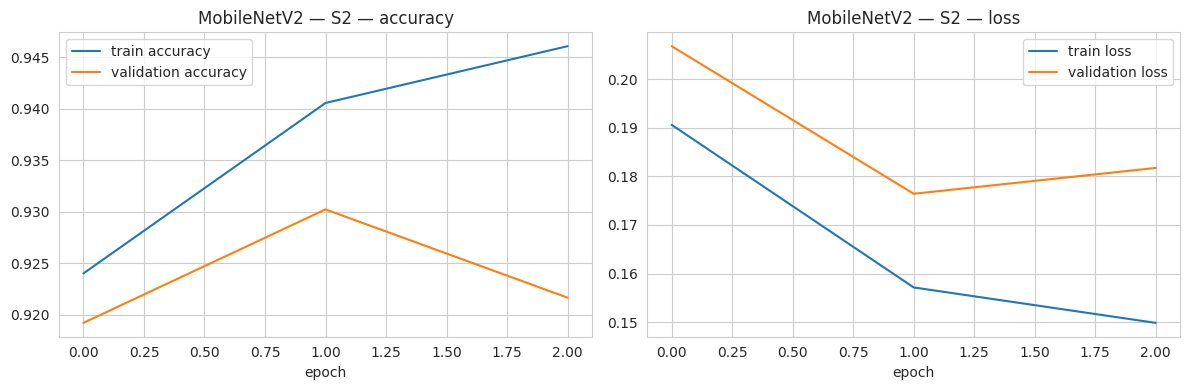

              precision    recall  f1-score   support

      glioma      0.934     0.853     0.892       300
  meningioma      0.832     0.859     0.846       306
     notumor      0.970     0.958     0.964       405
   pituitary      0.916     0.980     0.947       300

    accuracy                          0.916      1311
   macro avg      0.913     0.913     0.912      1311
weighted avg      0.917     0.916     0.916      1311

Recorded 'MobileNetV2 | S2': {'val_macro_f1': 0.9285, 'test_accuracy': 0.9161, 'test_macro_f1': 0.9121, 'recall_glioma': np.float64(0.8533), 'params_M': 2.587, 'cpu_latency_ms': 188.9}


{'run': 'MobileNetV2 | S2',
 'model': 'MobileNetV2',
 'track': 'A',
 'config': 'S2',
 'group': 'main',
 'val_accuracy': 0.9302325581395349,
 'val_macro_f1': 0.9285307134712909,
 'test_accuracy': 0.916094584286804,
 'test_macro_f1': 0.9121200713415134,
 'recall_glioma': np.float64(0.8533333333333334),
 'recall_meningioma': np.float64(0.8594771241830066),
 'recall_notumor': np.float64(0.9580246913580247),
 'recall_pituitary': np.float64(0.98),
 'params_M': 2.587,
 'size_MB': 23.1,
 'cpu_latency_ms': 188.9,
 'epochs': 3,
 'train_min': 4.2,
 'confusion_matrix': '[[256, 41, 0, 3], [9, 263, 12, 22], [7, 8, 388, 2], [2, 4, 0, 294]]',
 'model_path': '/content/drive/MyDrive/NeuroLens/models/MobileNetV2_S2.keras'}

In [22]:
plot_training(history_mobilenet_s2, "MobileNetV2 — S2")
evaluate_and_record(mobilenet_model, "MobileNetV2 | S2", "MobileNetV2", "A", "S2", history_mobilenet_s2, mobilenet_s2_time)

#### Step 8 — MobileNetV2: S1 vs. S2

Validation macro-F1 decides which stage is better for MobileNetV2; that one goes into the final comparison.

In [23]:
show_results("MobileNetV2")

,run,val_macro_f1,test_accuracy,test_macro_f1,recall_glioma,params_M,cpu_latency_ms,epochs
5,MobileNetV2 | S1,0.908817,0.877193,0.869628,0.780000,2.587,189.6,5
6,MobileNetV2 | S2,0.928531,0.916095,0.912120,0.853333,2.587,188.9,3


### 5.2 EfficientNetB0

A modern pretrained network (≈4.0M backbone parameters) that scales depth, width and input resolution together. It usually gives the best accuracy for its size, making it the strongest accuracy reference among the pretrained models.

#### Step 1 — Load the pretrained backbone

`include_top=False` removes the original ImageNet classifier (1,000 classes); we keep only the feature-extracting layers. `trainable = False` freezes all of them for S1.

In [24]:
efficientnet_base = EfficientNetB0(input_shape=IMG_SHAPE, include_top=False, weights="imagenet")
efficientnet_base.trainable = False

print("Backbone:", efficientnet_base.name)
print("Number of backbone layers:", len(efficientnet_base.layers))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Backbone: efficientnetb0
Number of backbone layers: 238


#### Step 2 — Add the input scaling and the new classification head

`training=False` keeps the backbone's BatchNorm layers in inference mode, also later during fine-tuning.

In [25]:
inputs = Input(shape=IMG_SHAPE)
x = layers.Rescaling(255.0)(inputs)                     # [0, 1] -> [0, 255]
x = efficientnet_base(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.4)(x)
outputs = Dense(NUM_CLASSES, activation="softmax")(x)

efficientnet_model = Model(inputs, outputs, name="efficientnetb0")
efficientnet_model.summary()

Model: "efficientnetb0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,378,535 (16.70 MB)

 Trainable params: 328,964 (1.25 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

#### Step 3 — S1: train the new head (backbone frozen)

Only the new head is trained, with learning rate 1e-3, for up to 15 epochs. **Early stopping** ends training when the validation loss stops improving for 4 epochs and restores the best weights; **ReduceLROnPlateau** halves the learning rate when progress stalls.

In [26]:
set_seeds()
efficientnet_model.compile(optimizer=Adam(learning_rate=1e-3), loss="categorical_crossentropy", metrics=["accuracy"])

start = time.time()
history_efficientnet_s1 = efficientnet_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_S1,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
    ],
)
efficientnet_s1_time = time.time() - start

Epoch 1/5
153/153 ━━━━━━━━━━━━━━━━━━━━ 117s 610ms/step - accuracy: 0.8004 - loss: 0.5086 - val_accuracy: 0.8690 - val_loss: 0.3379 - learning_rate: 0.0010
Epoch 2/5
153/153 ━━━━━━━━━━━━━━━━━━━━ 77s 505ms/step - accuracy: 0.8617 - loss: 0.3564 - val_accuracy: 0.8996 - val_loss: 0.3190 - learning_rate: 0.0010
Epoch 3/5
153/153 ━━━━━━━━━━━━━━━━━━━━ 77s 502ms/step - accuracy: 0.8907 - loss: 0.2940 - val_accuracy: 0.9070 - val_loss: 0.2666 - learning_rate: 0.0010
Epoch 4/5
153/153 ━━━━━━━━━━━━━━━━━━━━ 78s 509ms/step - accuracy: 0.9058 - loss: 0.2468 - val_accuracy: 0.9021 - val_loss: 0.2716 - learning_rate: 0.0010
Epoch 5/5
153/153 ━━━━━━━━━━━━━━━━━━━━ 79s 516ms/step - accuracy: 0.8960 - loss: 0.2508 - val_accuracy: 0.9033 - val_loss: 0.2593 - learning_rate: 0.0010


#### Step 4 — S1: evaluate and record

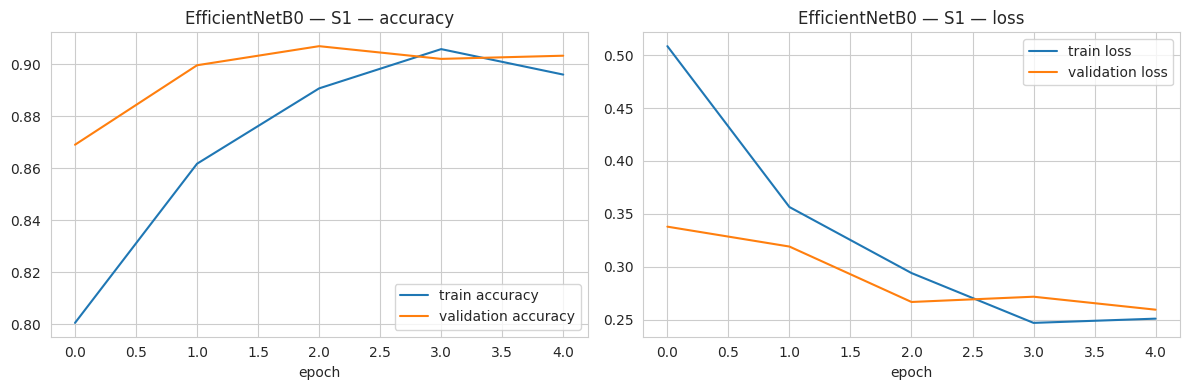

              precision    recall  f1-score   support

      glioma      0.914     0.813     0.861       300
  meningioma      0.838     0.729     0.780       306
     notumor      0.924     0.965     0.944       405
   pituitary      0.845     1.000     0.916       300

    accuracy                          0.883      1311
   macro avg      0.880     0.877     0.875      1311
weighted avg      0.884     0.883     0.880      1311

Recorded 'EfficientNetB0 | S1': {'val_macro_f1': 0.8998, 'test_accuracy': 0.8833, 'test_macro_f1': 0.8752, 'recall_glioma': np.float64(0.8133), 'params_M': 4.379, 'cpu_latency_ms': 344.3}


{'run': 'EfficientNetB0 | S1',
 'model': 'EfficientNetB0',
 'track': 'A',
 'config': 'S1',
 'group': 'main',
 'val_accuracy': 0.9033047735618115,
 'val_macro_f1': 0.8998075772627881,
 'test_accuracy': 0.8832951945080092,
 'test_macro_f1': 0.8752163631298491,
 'recall_glioma': np.float64(0.8133333333333334),
 'recall_meningioma': np.float64(0.7287581699346405),
 'recall_notumor': np.float64(0.9654320987654321),
 'recall_pituitary': np.float64(1.0),
 'params_M': 4.379,
 'size_MB': 21.0,
 'cpu_latency_ms': 344.3,
 'epochs': 5,
 'train_min': 7.2,
 'confusion_matrix': '[[244, 38, 2, 16], [14, 223, 30, 39], [9, 5, 391, 0], [0, 0, 0, 300]]',
 'model_path': '/content/drive/MyDrive/NeuroLens/models/EfficientNetB0_S1.keras'}

In [27]:
plot_training(history_efficientnet_s1, "EfficientNetB0 — S1")
evaluate_and_record(efficientnet_model, "EfficientNetB0 | S1", "EfficientNetB0", "A", "S1", history_efficientnet_s1, efficientnet_s1_time)

#### Step 5 — S2: unfreeze the top 20 backbone layers

The backbone is unlocked, then everything except the last 20 layers is frozen again. BatchNorm layers inside those 20 stay frozen. Keras counts every layer (including BatchNorm, activation and add layers), so the last 20 layers correspond roughly to the backbone's final block.

*If the Colab session restarted after S1, run the two commented lines first to reload the S1 model from Drive.*

In [28]:
# efficientnet_model = tf.keras.models.load_model(os.path.join(MODEL_DIR, "EfficientNetB0_S1.keras"))
# efficientnet_base = efficientnet_model.layers[2]

efficientnet_base.trainable = True
for layer in efficientnet_base.layers[:-FT_TOP_LAYERS]:
    layer.trainable = False
for layer in efficientnet_base.layers[-FT_TOP_LAYERS:]:
    if isinstance(layer, BatchNormalization):
        layer.trainable = False

trainable_params = sum(int(np.prod(w.shape)) for w in efficientnet_model.trainable_weights)
print(f"Trainable parameters: {trainable_params:,} of {efficientnet_model.count_params():,}")

Trainable parameters: 1,671,732 of 4,378,535


#### Step 6 — S2: fine-tune

The model must be **compiled again** after changing which layers are trainable. The learning rate is very small (1e-5) so the pretrained weights are only adjusted to MRI images, not overwritten. Up to 10 epochs, early stopping patience 3.

In [29]:
set_seeds()
efficientnet_model.compile(optimizer=Adam(learning_rate=1e-5), loss="categorical_crossentropy", metrics=["accuracy"])

start = time.time()
history_efficientnet_s2 = efficientnet_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_FT,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
    ],
)
efficientnet_s2_time = time.time() - start

Epoch 1/3
153/153 ━━━━━━━━━━━━━━━━━━━━ 113s 583ms/step - accuracy: 0.9273 - loss: 0.1909 - val_accuracy: 0.9204 - val_loss: 0.2141 - learning_rate: 1.0000e-05
Epoch 2/3
153/153 ━━━━━━━━━━━━━━━━━━━━ 78s 509ms/step - accuracy: 0.9332 - loss: 0.1815 - val_accuracy: 0.9204 - val_loss: 0.2035 - learning_rate: 1.0000e-05
Epoch 3/3
153/153 ━━━━━━━━━━━━━━━━━━━━ 76s 499ms/step - accuracy: 0.9381 - loss: 0.1705 - val_accuracy: 0.9241 - val_loss: 0.2016 - learning_rate: 1.0000e-05


#### Step 7 — S2: evaluate and record

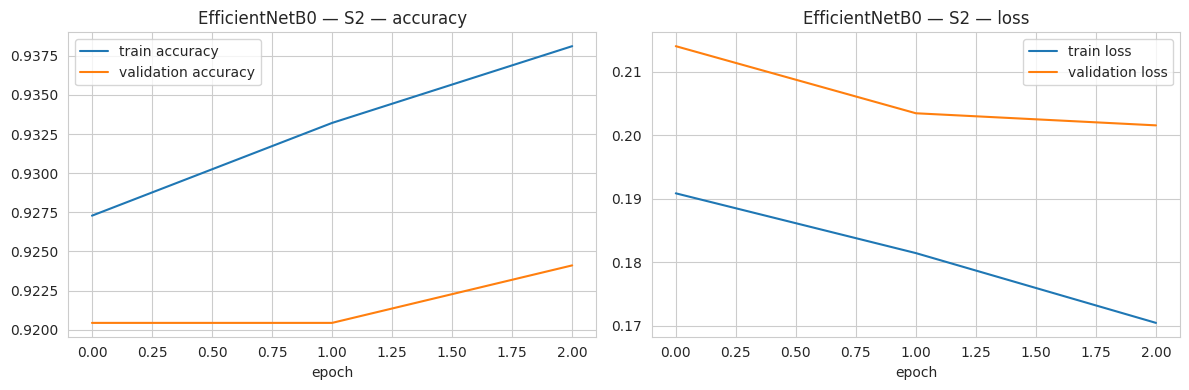

              precision    recall  f1-score   support

      glioma      0.911     0.853     0.881       300
  meningioma      0.855     0.830     0.842       306
     notumor      0.972     0.956     0.964       405
   pituitary      0.896     1.000     0.945       300

    accuracy                          0.913      1311
   macro avg      0.909     0.910     0.908      1311
weighted avg      0.913     0.913     0.912      1311

Recorded 'EfficientNetB0 | S2': {'val_macro_f1': 0.9212, 'test_accuracy': 0.913, 'test_macro_f1': 0.9081, 'recall_glioma': np.float64(0.8533), 'params_M': 4.379, 'cpu_latency_ms': 341.3}


{'run': 'EfficientNetB0 | S2',
 'model': 'EfficientNetB0',
 'track': 'A',
 'config': 'S2',
 'group': 'main',
 'val_accuracy': 0.9241126070991432,
 'val_macro_f1': 0.9212250960418196,
 'test_accuracy': 0.9130434782608695,
 'test_macro_f1': 0.9081152391952151,
 'recall_glioma': np.float64(0.8533333333333334),
 'recall_meningioma': np.float64(0.8300653594771242),
 'recall_notumor': np.float64(0.9555555555555556),
 'recall_pituitary': np.float64(1.0),
 'params_M': 4.379,
 'size_MB': 31.7,
 'cpu_latency_ms': 341.3,
 'epochs': 3,
 'train_min': 4.5,
 'confusion_matrix': '[[256, 36, 0, 8], [15, 254, 11, 26], [10, 7, 387, 1], [0, 0, 0, 300]]',
 'model_path': '/content/drive/MyDrive/NeuroLens/models/EfficientNetB0_S2.keras'}

In [30]:
plot_training(history_efficientnet_s2, "EfficientNetB0 — S2")
evaluate_and_record(efficientnet_model, "EfficientNetB0 | S2", "EfficientNetB0", "A", "S2", history_efficientnet_s2, efficientnet_s2_time)

#### Step 8 — EfficientNetB0: S1 vs. S2

Validation macro-F1 decides which stage is better for EfficientNetB0; that one goes into the final comparison.

In [31]:
show_results("EfficientNetB0")

,run,val_macro_f1,test_accuracy,test_macro_f1,recall_glioma,params_M,cpu_latency_ms,epochs
5,EfficientNetB0 | S1,0.899808,0.883295,0.875216,0.813333,4.379,344.3,5
6,EfficientNetB0 | S2,0.921225,0.913043,0.908115,0.853333,4.379,341.3,3


### 5.3 Xception

A large pretrained network (≈21M backbone parameters) built entirely from depth-wise separable convolutions. It tests whether a much bigger backbone gives a meaningful accuracy gain. Global **max** pooling is used in its head, as in the original elephant-classification experiments. Xception's default input size is 299 × 299, but 224 × 224 is used here so every model sees exactly the same images.

#### Step 1 — Load the pretrained backbone

`include_top=False` removes the original ImageNet classifier (1,000 classes); we keep only the feature-extracting layers. `trainable = False` freezes all of them for S1.

In [32]:
xception_base = Xception(input_shape=IMG_SHAPE, include_top=False, weights="imagenet")
xception_base.trainable = False

print("Backbone:", xception_base.name)
print("Number of backbone layers:", len(xception_base.layers))

83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Backbone: xception
Number of backbone layers: 132


#### Step 2 — Add the input scaling and the new classification head

`training=False` keeps the backbone's BatchNorm layers in inference mode, also later during fine-tuning.

In [33]:
inputs = Input(shape=IMG_SHAPE)
x = layers.Rescaling(2.0, offset=-1.0)(inputs)          # [0, 1] -> [-1, 1]
x = xception_base(x, training=False)
x = GlobalMaxPooling2D()(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.4)(x)
outputs = Dense(NUM_CLASSES, activation="softmax")(x)

xception_model = Model(inputs, outputs, name="xception")
xception_model.summary()

Model: "xception"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ xception (Functional)           │ (None, 7, 7, 2048)     │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling2d            │ (None, 2048)           │             0 │
│ (GlobalMaxPooling2D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,387,052 (81.59 MB)

 Trainable params: 525,572 (2.00 MB)

 Non-trainable params: 20,861,480 (79.58 MB)

#### Step 3 — S1: train the new head (backbone frozen)

Only the new head is trained, with learning rate 1e-3, for up to 15 epochs. **Early stopping** ends training when the validation loss stops improving for 4 epochs and restores the best weights; **ReduceLROnPlateau** halves the learning rate when progress stalls.

In [34]:
set_seeds()
xception_model.compile(optimizer=Adam(learning_rate=1e-3), loss="categorical_crossentropy", metrics=["accuracy"])

start = time.time()
history_xception_s1 = xception_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_S1,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
    ],
)
xception_s1_time = time.time() - start

Epoch 1/5
153/153 ━━━━━━━━━━━━━━━━━━━━ 140s 695ms/step - accuracy: 0.7077 - loss: 0.8587 - val_accuracy: 0.8409 - val_loss: 0.4329 - learning_rate: 0.0010
Epoch 2/5
153/153 ━━━━━━━━━━━━━━━━━━━━ 87s 569ms/step - accuracy: 0.8076 - loss: 0.5029 - val_accuracy: 0.8397 - val_loss: 0.3973 - learning_rate: 0.0010
Epoch 3/5
153/153 ━━━━━━━━━━━━━━━━━━━━ 87s 569ms/step - accuracy: 0.8342 - loss: 0.4260 - val_accuracy: 0.8825 - val_loss: 0.3332 - learning_rate: 0.0010
Epoch 4/5
153/153 ━━━━━━━━━━━━━━━━━━━━ 87s 564ms/step - accuracy: 0.8523 - loss: 0.3946 - val_accuracy: 0.8690 - val_loss: 0.3240 - learning_rate: 0.0010
Epoch 5/5
153/153 ━━━━━━━━━━━━━━━━━━━━ 85s 556ms/step - accuracy: 0.8482 - loss: 0.4013 - val_accuracy: 0.8813 - val_loss: 0.3012 - learning_rate: 0.0010


#### Step 4 — S1: evaluate and record

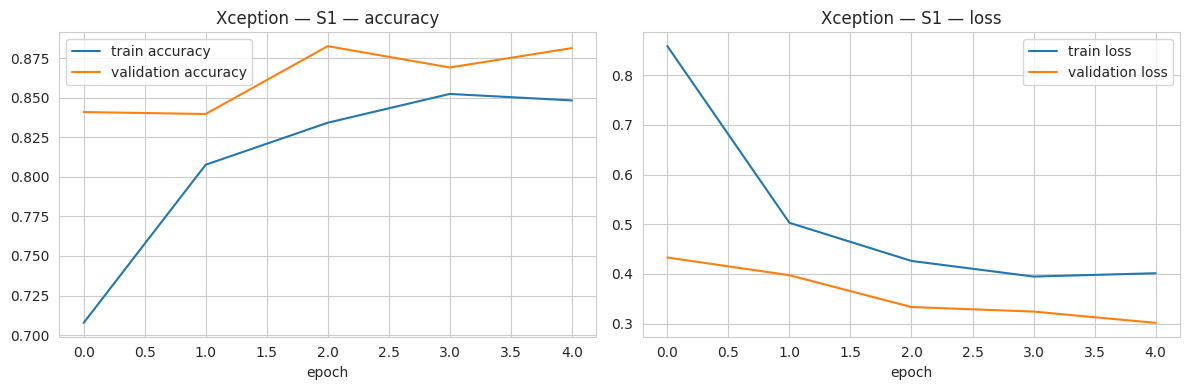

              precision    recall  f1-score   support

      glioma      0.907     0.750     0.821       300
  meningioma      0.704     0.801     0.749       306
     notumor      0.946     0.911     0.928       405
   pituitary      0.868     0.940     0.902       300

    accuracy                          0.855      1311
   macro avg      0.856     0.850     0.850      1311
weighted avg      0.863     0.855     0.856      1311

Recorded 'Xception | S1': {'val_macro_f1': 0.8806, 'test_accuracy': 0.8551, 'test_macro_f1': 0.8503, 'recall_glioma': np.float64(0.75), 'params_M': 21.387, 'cpu_latency_ms': 292.6}


{'run': 'Xception | S1',
 'model': 'Xception',
 'track': 'A',
 'config': 'S1',
 'group': 'main',
 'val_accuracy': 0.8812729498164015,
 'val_macro_f1': 0.8805680075481279,
 'test_accuracy': 0.855072463768116,
 'test_macro_f1': 0.850276311002562,
 'recall_glioma': np.float64(0.75),
 'recall_meningioma': np.float64(0.8006535947712419),
 'recall_notumor': np.float64(0.9111111111111111),
 'recall_pituitary': np.float64(0.94),
 'params_M': 21.387,
 'size_MB': 90.3,
 'cpu_latency_ms': 292.6,
 'epochs': 5,
 'train_min': 8.1,
 'confusion_matrix': '[[225, 62, 4, 9], [16, 245, 17, 28], [4, 26, 369, 6], [3, 15, 0, 282]]',
 'model_path': '/content/drive/MyDrive/NeuroLens/models/Xception_S1.keras'}

In [35]:
plot_training(history_xception_s1, "Xception — S1")
evaluate_and_record(xception_model, "Xception | S1", "Xception", "A", "S1", history_xception_s1, xception_s1_time)

#### Step 5 — S2: unfreeze the top 20 backbone layers

The backbone is unlocked, then everything except the last 20 layers is frozen again. BatchNorm layers inside those 20 stay frozen. Keras counts every layer (including BatchNorm, activation and add layers), so the last 20 layers correspond roughly to the backbone's final block.

*If the Colab session restarted after S1, run the two commented lines first to reload the S1 model from Drive.*

In [36]:
# xception_model = tf.keras.models.load_model(os.path.join(MODEL_DIR, "Xception_S1.keras"))
# xception_base = xception_model.layers[2]

xception_base.trainable = True
for layer in xception_base.layers[:-FT_TOP_LAYERS]:
    layer.trainable = False
for layer in xception_base.layers[-FT_TOP_LAYERS:]:
    if isinstance(layer, BatchNormalization):
        layer.trainable = False

trainable_params = sum(int(np.prod(w.shape)) for w in xception_model.trainable_weights)
print(f"Trainable parameters: {trainable_params:,} of {xception_model.count_params():,}")

Trainable parameters: 7,837,772 of 21,387,052


#### Step 6 — S2: fine-tune

The model must be **compiled again** after changing which layers are trainable. The learning rate is very small (1e-5) so the pretrained weights are only adjusted to MRI images, not overwritten. Up to 10 epochs, early stopping patience 3.

In [37]:
set_seeds()
xception_model.compile(optimizer=Adam(learning_rate=1e-5), loss="categorical_crossentropy", metrics=["accuracy"])

start = time.time()
history_xception_s2 = xception_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_FT,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
    ],
)
xception_s2_time = time.time() - start

Epoch 1/3
153/153 ━━━━━━━━━━━━━━━━━━━━ 114s 645ms/step - accuracy: 0.8913 - loss: 0.2909 - val_accuracy: 0.9009 - val_loss: 0.2336 - learning_rate: 1.0000e-05
Epoch 2/3
153/153 ━━━━━━━━━━━━━━━━━━━━ 89s 579ms/step - accuracy: 0.9056 - loss: 0.2506 - val_accuracy: 0.9290 - val_loss: 0.2097 - learning_rate: 1.0000e-05
Epoch 3/3
153/153 ━━━━━━━━━━━━━━━━━━━━ 88s 578ms/step - accuracy: 0.9205 - loss: 0.2142 - val_accuracy: 0.9266 - val_loss: 0.1991 - learning_rate: 1.0000e-05


#### Step 7 — S2: evaluate and record

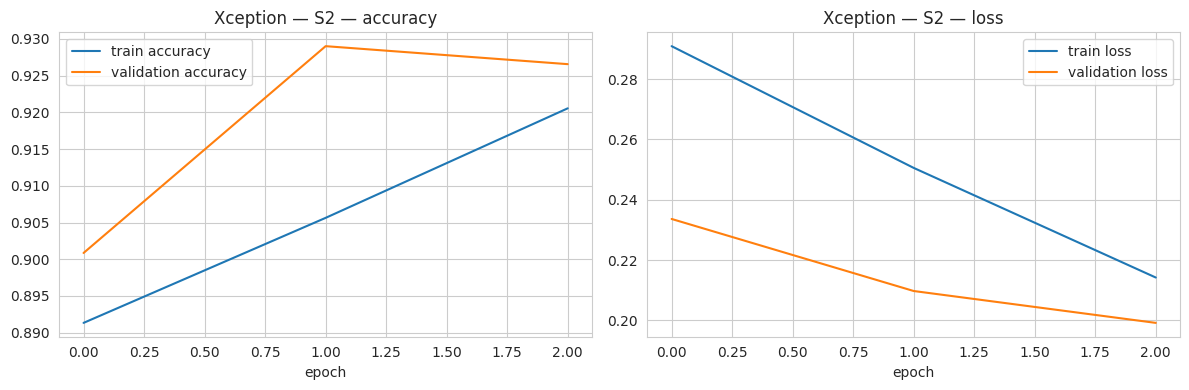

              precision    recall  f1-score   support

      glioma      0.844     0.883     0.863       300
  meningioma      0.835     0.778     0.805       306
     notumor      0.955     0.936     0.945       405
   pituitary      0.914     0.960     0.937       300

    accuracy                          0.892      1311
   macro avg      0.887     0.889     0.888      1311
weighted avg      0.892     0.892     0.892      1311

Recorded 'Xception | S2': {'val_macro_f1': 0.9245, 'test_accuracy': 0.8924, 'test_macro_f1': 0.8876, 'recall_glioma': np.float64(0.8833), 'params_M': 21.387, 'cpu_latency_ms': 280.8}


{'run': 'Xception | S2',
 'model': 'Xception',
 'track': 'A',
 'config': 'S2',
 'group': 'main',
 'val_accuracy': 0.9265605875152999,
 'val_macro_f1': 0.9245231472373416,
 'test_accuracy': 0.8924485125858124,
 'test_macro_f1': 0.8875823142446897,
 'recall_glioma': np.float64(0.8833333333333333),
 'recall_meningioma': np.float64(0.7777777777777778),
 'recall_notumor': np.float64(0.9358024691358025),
 'recall_pituitary': np.float64(0.96),
 'params_M': 21.387,
 'size_MB': 148.8,
 'cpu_latency_ms': 280.8,
 'epochs': 3,
 'train_min': 4.9,
 'confusion_matrix': '[[265, 28, 3, 4], [35, 238, 15, 18], [9, 12, 379, 5], [5, 7, 0, 288]]',
 'model_path': '/content/drive/MyDrive/NeuroLens/models/Xception_S2.keras'}

In [38]:
plot_training(history_xception_s2, "Xception — S2")
evaluate_and_record(xception_model, "Xception | S2", "Xception", "A", "S2", history_xception_s2, xception_s2_time)

#### Step 8 — Xception: S1 vs. S2

Validation macro-F1 decides which stage is better for Xception; that one goes into the final comparison.

In [39]:
show_results("Xception")

,run,val_macro_f1,test_accuracy,test_macro_f1,recall_glioma,params_M,cpu_latency_ms,epochs
5,Xception | S1,0.880568,0.855072,0.850276,0.750000,21.387,292.6,5
6,Xception | S2,0.924523,0.892449,0.887582,0.883333,21.387,280.8,3


## 6. Track B — Models trained from scratch

These models start from random weights and learn only from the brain MRI training data, so they use a higher learning rate and more epochs than fine-tuning.

### 6.1 Custom CNN — default settings

A plain CNN: four blocks of Conv → BatchNorm → MaxPool (32, 64, 128, 256 filters), then a flattened dense head. It is the simple from-scratch reference: what a standard CNN achieves without pretrained weights or special design.

#### Step 1 — Build the model

In [40]:
cnn_model = Sequential([
    Input(shape=IMG_SHAPE),

    Conv2D(32, (3, 3), activation="relu"), BatchNormalization(), MaxPooling2D((2, 2)),     # block 1
    Conv2D(64, (3, 3), activation="relu"), BatchNormalization(), MaxPooling2D((2, 2)),     # block 2
    Conv2D(128, (3, 3), activation="relu"), BatchNormalization(), MaxPooling2D((2, 2)),    # block 3
    Conv2D(256, (3, 3), activation="relu"), BatchNormalization(), MaxPooling2D((2, 2)),    # block 4

    Flatten(),
    Dense(256, activation="relu"), Dropout(0.5),
    Dense(128, activation="relu"), Dropout(0.3),
    Dense(NUM_CLASSES, activation="softmax"),
], name="custom_cnn")

cnn_model.summary()

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 52, 52, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 24, 24, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │     9,437,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,861,188 (37.62 MB)

 Trainable params: 9,860,228 (37.61 MB)

 Non-trainable params: 960 (3.75 KB)

#### Step 2 — Train

Learning rate 1e-3, up to 40 epochs, early stopping patience 6.

In [41]:
set_seeds()
cnn_model.compile(optimizer=Adam(learning_rate=1e-3), loss="categorical_crossentropy", metrics=["accuracy"])

start = time.time()
history_cnn = cnn_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_SCRATCH,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
    ],
)
cnn_time = time.time() - start

Epoch 1/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 94s 529ms/step - accuracy: 0.4867 - loss: 3.4558 - val_accuracy: 0.2644 - val_loss: 7.3428 - learning_rate: 0.0010
Epoch 2/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 79s 515ms/step - accuracy: 0.5210 - loss: 1.1983 - val_accuracy: 0.3562 - val_loss: 1.4371 - learning_rate: 0.0010
Epoch 3/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 79s 515ms/step - accuracy: 0.4449 - loss: 1.2536 - val_accuracy: 0.5165 - val_loss: 1.0870 - learning_rate: 0.0010
Epoch 4/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 81s 512ms/step - accuracy: 0.4673 - loss: 1.2152 - val_accuracy: 0.5275 - val_loss: 0.9723 - learning_rate: 0.0010
Epoch 5/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 83s 538ms/step - accuracy: 0.4122 - loss: 1.2333 - val_accuracy: 0.4676 - val_loss: 1.0962 - learning_rate: 0.0010
Epoch 6/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 81s 529ms/step - accuracy: 0.4408 - loss: 1.2265 - val_accuracy: 0.6059 - val_loss: 1.0098 - learning_rate: 0.0010
Epoch 7/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 502ms/step - accuracy: 0.46

#### Step 3 — Evaluate and record

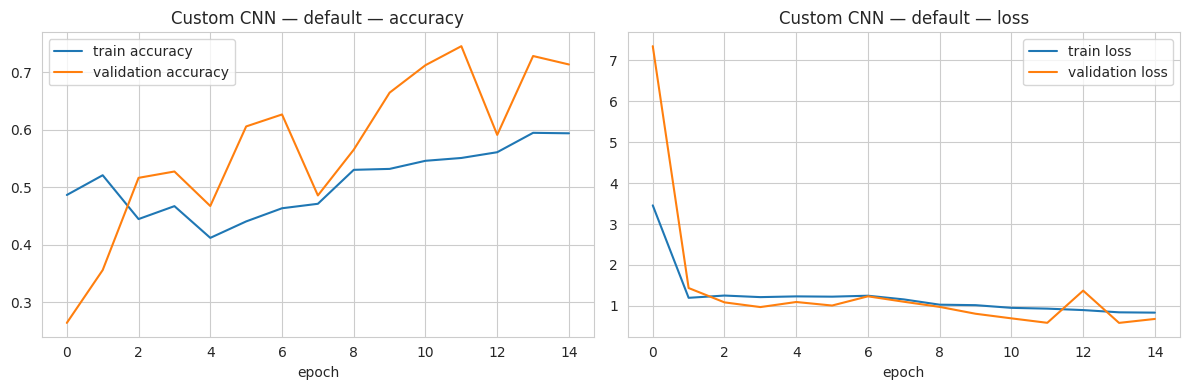

              precision    recall  f1-score   support

      glioma      0.693     0.610     0.649       300
  meningioma      0.483     0.232     0.313       306
     notumor      0.818     0.965     0.886       405
   pituitary      0.699     0.983     0.817       300

    accuracy                          0.717      1311
   macro avg      0.673     0.698     0.666      1311
weighted avg      0.684     0.717     0.682      1311

Recorded 'Custom CNN | default': {'val_macro_f1': 0.6996, 'test_accuracy': 0.717, 'test_macro_f1': 0.6663, 'recall_glioma': np.float64(0.61), 'params_M': 9.861, 'cpu_latency_ms': 50.1}


{'run': 'Custom CNN | default',
 'model': 'Custom CNN',
 'track': 'B',
 'config': 'default',
 'group': 'main',
 'val_accuracy': 0.7282741738066095,
 'val_macro_f1': 0.6995971238790952,
 'test_accuracy': 0.7170099160945843,
 'test_macro_f1': 0.6662984207889293,
 'recall_glioma': np.float64(0.61),
 'recall_meningioma': np.float64(0.23202614379084968),
 'recall_notumor': np.float64(0.9654320987654321),
 'recall_pituitary': np.float64(0.9833333333333333),
 'params_M': 9.861,
 'size_MB': 118.4,
 'cpu_latency_ms': 50.1,
 'epochs': 15,
 'train_min': 20.3,
 'confusion_matrix': '[[183, 65, 0, 52], [81, 71, 86, 68], [0, 7, 391, 7], [0, 4, 1, 295]]',
 'model_path': '/content/drive/MyDrive/NeuroLens/models/Custom_CNN_default.keras'}

In [42]:
plot_training(history_cnn, "Custom CNN — default")
evaluate_and_record(cnn_model, "Custom CNN | default", "Custom CNN", "B", "default", history_cnn, cnn_time)

### 6.2 Custom CNN — hyperparameter tuning

#### Step 1 — Install KerasTuner

In [43]:
!pip install -q -U keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 5.5 MB/s eta 0:00:00


#### Step 2 — Define the search space

KerasTuner needs a function that builds one model from a set of hyperparameter values (`hp`). It has the same four-block structure as the default CNN, but these settings are left open for the tuner to choose:

| Hyperparameter | Values searched | Why |
|---|---|---|
| `base_filters` | 16, 32, 48 | network width (filters double in each block) |
| `head` | flatten, global average pooling | the flattened head holds most of the default model's ~9.9M parameters and tends to overfit; pooling is much smaller |
| `dense_units` | 128, 256, 512 | size of the dense head |
| `dropout` | 0.3 – 0.6 | regularisation strength |
| `learning_rate` | 1e-4 – 1e-3 (log scale) | step size of the optimiser |

In [44]:
import keras_tuner as kt

def build_tunable_cnn(hp):
    base_filters = hp.Choice("base_filters", [16, 32, 48])
    head = hp.Choice("head", ["flatten", "gap"])
    dense_units = hp.Choice("dense_units", [128, 256, 512])
    dropout = hp.Float("dropout", 0.3, 0.6, step=0.1)
    learning_rate = hp.Float("learning_rate", 1e-4, 1e-3, sampling="log")

    model = Sequential(name="custom_cnn_tuned")
    model.add(Input(shape=IMG_SHAPE))
    model.add(Conv2D(base_filters, (3, 3), activation="relu"))
    model.add(BatchNormalization())
    model.add(MaxPooling2D((2, 2)))
    model.add(Conv2D(base_filters * 2, (3, 3), activation="relu"))
    model.add(BatchNormalization())
    model.add(MaxPooling2D((2, 2)))
    model.add(Conv2D(base_filters * 4, (3, 3), activation="relu"))
    model.add(BatchNormalization())
    model.add(MaxPooling2D((2, 2)))
    model.add(Conv2D(base_filters * 8, (3, 3), activation="relu"))
    model.add(BatchNormalization())
    model.add(MaxPooling2D((2, 2)))

    if head == "flatten":
        model.add(Flatten())
    else:
        model.add(GlobalAveragePooling2D())
    model.add(Dense(dense_units, activation="relu"))
    model.add(Dropout(dropout))
    model.add(Dense(dense_units // 2, activation="relu"))
    model.add(Dropout(0.3))
    model.add(Dense(NUM_CLASSES, activation="softmax"))

    model.compile(optimizer=Adam(learning_rate=learning_rate), loss="categorical_crossentropy", metrics=["accuracy"])
    return model

#### Step 3 — Run the search

Random search over 10 combinations, keeping the one with the best **validation accuracy** (the test set is not used). Each trial trains for at most 15 epochs with early stopping to keep the search affordable. The search is stored on Google Drive, so if Colab disconnects, re-running this cell continues the search instead of restarting it.

In [45]:
tuner = kt.RandomSearch(
    build_tunable_cnn,
    objective="val_accuracy",
    max_trials=TUNER_TRIALS,
    executions_per_trial=1,
    seed=SEED,
    directory=os.path.join(OUTPUT_DIR, "tuner_dir"),
    project_name="custom_cnn_quick" if QUICK_RUN else "custom_cnn",
)

start = time.time()
tuner.search(
    train_gen,
    validation_data=val_gen,
    epochs=TUNER_EPOCHS,
    callbacks=[EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)],
)
print(f"Search took {(time.time() - start) / 60:.1f} min")

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Best hyperparameters:", best_hp.values)
tuner.results_summary(num_trials=5)

Trial 3 Complete [00h 07m 20s]
val_accuracy: 0.7233782410621643

Best val_accuracy So Far: 0.7343941330909729
Total elapsed time: 00h 20m 31s
Search took 20.5 min
Best hyperparameters: {'base_filters': 32, 'head': 'flatten', 'dense_units': 256, 'dropout': 0.3, 'learning_rate': 0.0007731576839806804}
Results summary
Results in /content/drive/MyDrive/NeuroLens/tuner_dir/custom_cnn_quick
Showing 5 best trials
Objective(name="val_accuracy", direction="max")

Trial 0 summary
Hyperparameters:
base_filters: 32
head: flatten
dense_units: 256
dropout: 0.3
learning_rate: 0.0007731576839806804
Score: 0.7343941330909729

Trial 2 summary
Hyperparameters:
base_filters: 48
head: gap
dense_units: 512
dropout: 0.3
learning_rate: 0.0009245261253931151
Score: 0.7233782410621643

Trial 1 summary
Hyperparameters:
base_filters: 32
head: gap
dense_units: 128
dropout: 0.4
learning_rate: 0.00017519340871097286
Score: 0.48959606885910034


#### Step 4 — Build the best model

`tuner.hypermodel.build(best_hp)` builds a fresh, untrained model with the best settings found.

In [46]:
cnn_tuned_model = tuner.hypermodel.build(best_hp)
cnn_tuned_model.summary()

Model: "custom_cnn_tuned"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 52, 52, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 24, 24, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │     9,437,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,861,188 (37.62 MB)

 Trainable params: 9,860,228 (37.61 MB)

 Non-trainable params: 960 (3.75 KB)

#### Step 5 — Train the best model

The search trials were shortened to save time, so the best settings are now trained from scratch with the same full schedule as the default CNN (up to 40 epochs, early stopping patience 6). This makes the default and tuned CNNs directly comparable. The learning rate chosen by the tuner is already set in the model.

In [47]:
set_seeds()
start = time.time()
history_cnn_tuned = cnn_tuned_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_SCRATCH,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
    ],
)
cnn_tuned_time = time.time() - start

Epoch 1/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 112s 604ms/step - accuracy: 0.5547 - loss: 2.2078 - val_accuracy: 0.2485 - val_loss: 2.1057 - learning_rate: 7.7316e-04
Epoch 2/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 80s 520ms/step - accuracy: 0.5709 - loss: 1.1493 - val_accuracy: 0.4015 - val_loss: 2.2211 - learning_rate: 7.7316e-04
Epoch 3/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 81s 528ms/step - accuracy: 0.5942 - loss: 0.9570 - val_accuracy: 0.5667 - val_loss: 1.2895 - learning_rate: 7.7316e-04
Epoch 4/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 80s 522ms/step - accuracy: 0.6601 - loss: 0.8880 - val_accuracy: 0.7295 - val_loss: 0.6743 - learning_rate: 7.7316e-04
Epoch 5/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 82s 531ms/step - accuracy: 0.6871 - loss: 0.8153 - val_accuracy: 0.8250 - val_loss: 0.5143 - learning_rate: 7.7316e-04
Epoch 6/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 81s 529ms/step - accuracy: 0.7063 - loss: 0.7396 - val_accuracy: 0.7834 - val_loss: 0.5985 - learning_rate: 7.7316e-04
Epoch 7/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 84s 5

#### Step 6 — Evaluate and record, then compare default vs. tuned

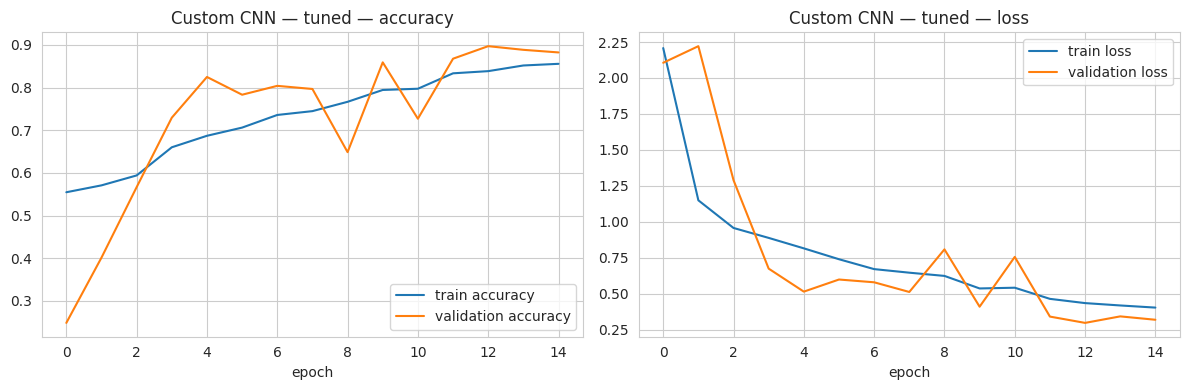

              precision    recall  f1-score   support

      glioma      0.930     0.707     0.803       300
  meningioma      0.684     0.601     0.640       306
     notumor      0.814     0.953     0.878       405
   pituitary      0.868     0.983     0.922       300

    accuracy                          0.822      1311
   macro avg      0.824     0.811     0.811      1311
weighted avg      0.823     0.822     0.815      1311

Recorded 'Custom CNN | tuned': {'val_macro_f1': 0.8947, 'test_accuracy': 0.8215, 'test_macro_f1': 0.8108, 'recall_glioma': np.float64(0.7067), 'params_M': 9.861, 'cpu_latency_ms': 51.0}


{'run': 'Custom CNN | tuned',
 'model': 'Custom CNN',
 'track': 'B',
 'config': 'tuned',
 'group': 'main',
 'val_accuracy': 0.8971848225214198,
 'val_macro_f1': 0.8946569521896014,
 'test_accuracy': 0.8215102974828375,
 'test_macro_f1': 0.8107940163150273,
 'recall_glioma': np.float64(0.7066666666666667),
 'recall_meningioma': np.float64(0.6013071895424836),
 'recall_notumor': np.float64(0.9530864197530864),
 'recall_pituitary': np.float64(0.9833333333333333),
 'params_M': 9.861,
 'size_MB': 118.4,
 'cpu_latency_ms': 51.0,
 'epochs': 15,
 'train_min': 21.8,
 'confusion_matrix': '[[212, 77, 0, 11], [4, 184, 86, 32], [12, 5, 386, 2], [0, 3, 2, 295]]',
 'model_path': '/content/drive/MyDrive/NeuroLens/models/Custom_CNN_tuned.keras'}

In [48]:
plot_training(history_cnn_tuned, "Custom CNN — tuned")
evaluate_and_record(cnn_tuned_model, "Custom CNN | tuned", "Custom CNN", "B", "tuned", history_cnn_tuned, cnn_tuned_time)

In [49]:
show_results("Custom CNN")

,run,val_macro_f1,test_accuracy,test_macro_f1,recall_glioma,params_M,cpu_latency_ms,epochs
6,Custom CNN | default,0.699597,0.71701,0.666298,0.610000,9.861,50.1,15
7,Custom CNN | tuned,0.894657,0.82151,0.810794,0.706667,9.861,51.0,15


### 6.3 Fibonacci-Net (Roy et al. 2025)

A lightweight CNN (≈0.38M parameters) designed specifically for class-imbalanced brain tumor MRI. Its key features:
- **Fibonacci filter counts** across seven blocks: 21, 34, 55, 89, 144, 233, 377;
- **Avg-2Max pooling**, AveragePooling(x) − 2·MaxPooling(x), which emphasises edges, used inside two **Parallel Concatenation Blocks** — skip connections from block 2 → 4 and from block 3 → 5;
- **depth-wise separable convolutions** in the last two blocks, to keep the parameter count low.

Fibonacci-Net has no pretrained weights, so instead of S1/S2 it is tuned by trying **three learning rates** (1e-3, 3e-4, 1e-4). Each run creates a fresh copy of the same architecture.

#### Step 1 — Custom layers

Keras has no built-in Avg-2Max pooling or this depth-wise separable block, so they are defined as custom layers. They are registered with Keras (`register_keras_serializable` + `get_config`) so the trained model can be saved and loaded again later — for example by the dashboard.

In [50]:
@tf.keras.utils.register_keras_serializable()
class Avg2MaxPooling(layers.Layer):
    """Avg-2Max pooling: AveragePooling(x) - 2 * MaxPooling(x)."""
    def __init__(self, pool_size=3, strides=2, padding="same", **kwargs):
        super().__init__(**kwargs)
        self.pool_size, self.strides, self.padding = pool_size, strides, padding
        self.avg_pool = layers.AveragePooling2D(pool_size, strides, padding)
        self.max_pool = layers.MaxPooling2D(pool_size, strides, padding)

    def call(self, inputs):
        return self.avg_pool(inputs) - (self.max_pool(inputs) + self.max_pool(inputs))

    def get_config(self):
        config = super().get_config()
        config.update({"pool_size": self.pool_size, "strides": self.strides, "padding": self.padding})
        return config


@tf.keras.utils.register_keras_serializable()
class DepthwiseSeparableConv(layers.Layer):
    """Depth-wise separable convolution + BatchNorm + ReLU."""
    def __init__(self, filters, kernel_size=3, strides=1, **kwargs):
        super().__init__(**kwargs)
        self.filters, self.kernel_size, self.strides = filters, kernel_size, strides

    def build(self, input_shape):
        self.dw = layers.DepthwiseConv2D(self.kernel_size, self.strides, padding="same")
        self.pw = layers.Conv2D(self.filters, 1, strides=1)
        self.bn = layers.BatchNormalization()
        super().build(input_shape)

    def call(self, inputs):
        return tf.nn.relu(self.bn(self.pw(self.dw(inputs))))

    def get_config(self):
        config = super().get_config()
        config.update({"filters": self.filters, "kernel_size": self.kernel_size, "strides": self.strides})
        return config

#### Step 2 — The Fibonacci-Net architecture

This function builds the network block by block. It is called once for each learning rate below, so each run starts from fresh random weights.

In [51]:
def create_fibonacci_net():
    inputs = layers.Input(shape=IMG_SHAPE)

    # Block 1 (21 filters)
    x = layers.Conv2D(21, 3, padding="same")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D(2)(x)                        # 112 x 112

    # Block 2 (34 filters)
    x = layers.Conv2D(34, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x2 = layers.ReLU()(x)                                # kept for skip connection 1
    x = layers.MaxPooling2D(2)(x2)                       # 56 x 56

    # Block 3 (55 filters)
    x = layers.Conv2D(55, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x3 = layers.ReLU()(x)                                # kept for skip connection 2
    x = layers.MaxPooling2D(2)(x3)                       # 28 x 28

    # Parallel Concatenation Block 1: block 2 -> block 4
    pcb1 = layers.Conv2D(24, 3, padding="same")(x2)
    pcb1 = Avg2MaxPooling()(pcb1)
    pcb1 = layers.Conv2D(24, 3, padding="same")(pcb1)
    pcb1 = Avg2MaxPooling()(pcb1)

    # Block 4 (89 filters) + skip connection 1
    x = layers.Conv2D(89, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D(2)(x)                        # 14 x 14
    x = layers.concatenate([x, layers.Resizing(14, 14)(pcb1)])

    # Parallel Concatenation Block 2: block 3 -> block 5
    pcb2 = layers.Conv2D(24, 3, padding="same")(x3)
    pcb2 = Avg2MaxPooling()(pcb2)
    pcb2 = layers.Conv2D(24, 3, padding="same")(pcb2)
    pcb2 = Avg2MaxPooling()(pcb2)

    # Block 5 (144 filters) + skip connection 2
    x = layers.Conv2D(144, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D(2)(x)                        # 7 x 7
    x = layers.concatenate([x, layers.Resizing(7, 7)(pcb2)])

    # Blocks 6 and 7 (233 and 377 filters, depth-wise separable)
    x = DepthwiseSeparableConv(233)(x)
    x = DepthwiseSeparableConv(377)(x)

    # Classification head
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return Model(inputs, outputs, name="fibonacci_net")


create_fibonacci_net().summary()

Model: "fibonacci_net"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 224, 224,  │        588 │ input_layer_2[0]… │
│                     │ 21)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 224, 224,  │         84 │ conv2d_8[0][0]    │
│ (BatchNormalizatio… │ 21)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 224, 224,  │          0 │ batch_normalizat… │
│                     │ 21)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, 112, 112,  │          0 │ re_lu[0][0]       │
│ (MaxPooling2D)      │ 21)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 112, 112,  │      6,460 │ max_pooling2d_8[… │
│                     │ 34)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        136 │ conv2d_9[0][0]    │
│ (BatchNormalizatio… │ 34)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 34)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_9     │ (None, 56, 56,    │          0 │ re_lu_1[0][0]     │
│ (MaxPooling2D)      │ 34)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 56, 56,    │     16,885 │ max_pooling2d_9[… │
│                     │ 55)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        220 │ conv2d_10[0][0]   │
│ (BatchNormalizatio… │ 55)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 55)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_10    │ (None, 28, 28,    │          0 │ re_lu_2[0][0]     │
│ (MaxPooling2D)      │ 55)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 112, 112,  │      7,368 │ re_lu_1[0][0]     │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 28, 28,    │     44,144 │ max_pooling2d_10… │
│                     │ 89)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ avg2_max_pooling    │ (None, 56, 56,    │          0 │ conv2d_11[0][0]   │
│ (Avg2MaxPooling)    │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │        356 │ conv2d_13[0][0] 

 Total params: 381,286 (1.45 MB)

 Trainable params: 379,380 (1.45 MB)

 Non-trainable params: 1,906 (7.45 KB)

#### Step 3 — Train with learning rate 1e-3

Up to 40 epochs, early stopping patience 6.

In [52]:
set_seeds()
fib_1em3_model = create_fibonacci_net()
fib_1em3_model.compile(optimizer=Adam(learning_rate=1e-3), loss="categorical_crossentropy", metrics=["accuracy"])

start = time.time()
history_fib_1em3 = fib_1em3_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_SCRATCH,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
    ],
)
fib_1em3_time = time.time() - start

Epoch 1/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 112s 587ms/step - accuracy: 0.7469 - loss: 0.6309 - val_accuracy: 0.2827 - val_loss: 1.3726 - learning_rate: 0.0010
Epoch 2/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 83s 543ms/step - accuracy: 0.8399 - loss: 0.4187 - val_accuracy: 0.2607 - val_loss: 1.3388 - learning_rate: 0.0010
Epoch 3/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 81s 531ms/step - accuracy: 0.8656 - loss: 0.3527 - val_accuracy: 0.8140 - val_loss: 0.5274 - learning_rate: 0.0010
Epoch 4/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 83s 542ms/step - accuracy: 0.8881 - loss: 0.3046 - val_accuracy: 0.8800 - val_loss: 0.3362 - learning_rate: 0.0010
Epoch 5/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 83s 543ms/step - accuracy: 0.9011 - loss: 0.2579 - val_accuracy: 0.4235 - val_loss: 2.2698 - learning_rate: 0.0010
Epoch 6/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 84s 546ms/step - accuracy: 0.9116 - loss: 0.2386 - val_accuracy: 0.7821 - val_loss: 0.7805 - learning_rate: 0.0010
Epoch 7/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 81s 529ms/step - accuracy: 0.

#### Step 4 — Evaluate and record (learning rate 1e-3)

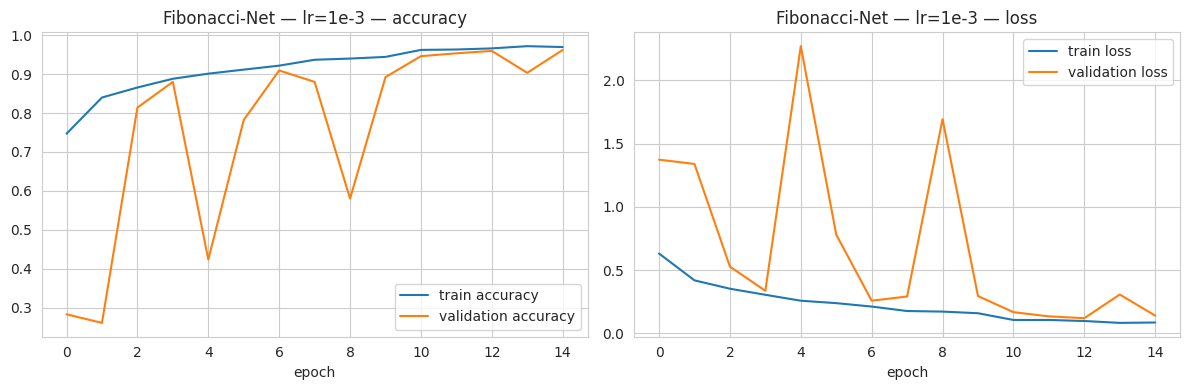

              precision    recall  f1-score   support

      glioma      0.988     0.827     0.900       300
  meningioma      0.812     0.948     0.875       306
     notumor      0.987     0.928     0.957       405
   pituitary      0.929     0.997     0.961       300

    accuracy                          0.925      1311
   macro avg      0.929     0.925     0.923      1311
weighted avg      0.933     0.925     0.926      1311

Recorded 'Fibonacci-Net | lr=0.001': {'val_macro_f1': 0.9589, 'test_accuracy': 0.9252, 'test_macro_f1': 0.9233, 'recall_glioma': np.float64(0.8267), 'params_M': 0.381, 'cpu_latency_ms': 75.0}


{'run': 'Fibonacci-Net | lr=0.001',
 'model': 'Fibonacci-Net',
 'track': 'B',
 'config': 'lr=0.001',
 'group': 'main',
 'val_accuracy': 0.9596083231334149,
 'val_macro_f1': 0.9589145117338861,
 'test_accuracy': 0.9252479023646072,
 'test_macro_f1': 0.9232876861978344,
 'recall_glioma': np.float64(0.8266666666666667),
 'recall_meningioma': np.float64(0.9477124183006536),
 'recall_notumor': np.float64(0.928395061728395),
 'recall_pituitary': np.float64(0.9966666666666667),
 'params_M': 0.381,
 'size_MB': 4.8,
 'cpu_latency_ms': 75.0,
 'epochs': 15,
 'train_min': 21.1,
 'confusion_matrix': '[[248, 40, 0, 12], [0, 290, 5, 11], [3, 26, 376, 0], [0, 1, 0, 299]]',
 'model_path': '/content/drive/MyDrive/NeuroLens/models/Fibonacci-Net_lr=0.001.keras'}

In [53]:
plot_training(history_fib_1em3, "Fibonacci-Net — lr=1e-3")
evaluate_and_record(fib_1em3_model, "Fibonacci-Net | lr=0.001", "Fibonacci-Net", "B", "lr=0.001", history_fib_1em3, fib_1em3_time)

#### Step 5 — Train with learning rate 3e-4

Up to 40 epochs, early stopping patience 6.

In [54]:
set_seeds()
fib_3em4_model = create_fibonacci_net()
fib_3em4_model.compile(optimizer=Adam(learning_rate=3e-4), loss="categorical_crossentropy", metrics=["accuracy"])

start = time.time()
history_fib_3em4 = fib_3em4_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_SCRATCH,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
    ],
)
fib_3em4_time = time.time() - start

Epoch 1/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 100s 560ms/step - accuracy: 0.7241 - loss: 0.6901 - val_accuracy: 0.3170 - val_loss: 1.3856 - learning_rate: 3.0000e-04
Epoch 2/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 83s 541ms/step - accuracy: 0.8260 - loss: 0.4550 - val_accuracy: 0.3476 - val_loss: 1.2988 - learning_rate: 3.0000e-04
Epoch 3/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 82s 535ms/step - accuracy: 0.8703 - loss: 0.3530 - val_accuracy: 0.4382 - val_loss: 1.0282 - learning_rate: 3.0000e-04
Epoch 4/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 82s 532ms/step - accuracy: 0.8868 - loss: 0.3038 - val_accuracy: 0.5924 - val_loss: 1.0093 - learning_rate: 3.0000e-04
Epoch 5/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 83s 540ms/step - accuracy: 0.8948 - loss: 0.2799 - val_accuracy: 0.8458 - val_loss: 0.3970 - learning_rate: 3.0000e-04
Epoch 6/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 83s 542ms/step - accuracy: 0.9120 - loss: 0.2379 - val_accuracy: 0.8727 - val_loss: 0.3645 - learning_rate: 3.0000e-04
Epoch 7/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 80s 5

#### Step 6 — Evaluate and record (learning rate 3e-4)

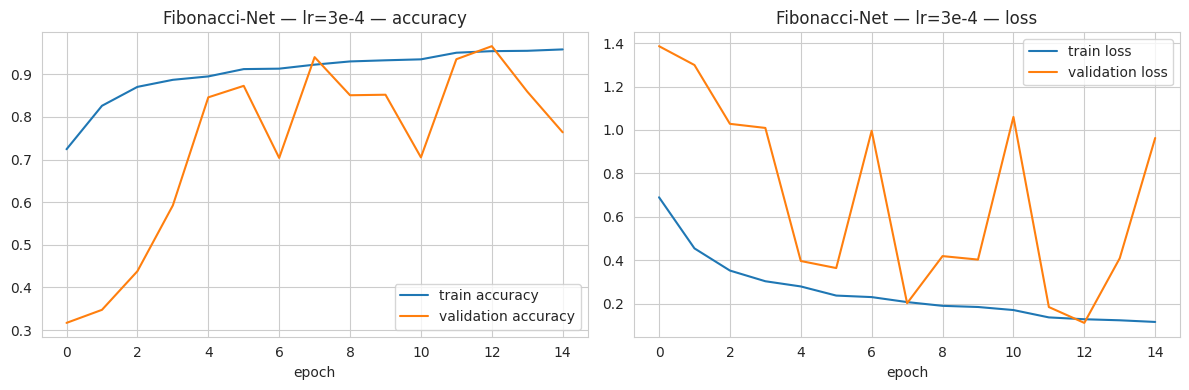

              precision    recall  f1-score   support

      glioma      0.973     0.947     0.959       300
  meningioma      0.921     0.918     0.920       306
     notumor      0.966     0.975     0.971       405
   pituitary      0.970     0.987     0.979       300

    accuracy                          0.958      1311
   macro avg      0.958     0.957     0.957      1311
weighted avg      0.958     0.958     0.958      1311

Recorded 'Fibonacci-Net | lr=0.0003': {'val_macro_f1': 0.9653, 'test_accuracy': 0.958, 'test_macro_f1': 0.9571, 'recall_glioma': np.float64(0.9467), 'params_M': 0.381, 'cpu_latency_ms': 74.5}


{'run': 'Fibonacci-Net | lr=0.0003',
 'model': 'Fibonacci-Net',
 'track': 'B',
 'config': 'lr=0.0003',
 'group': 'main',
 'val_accuracy': 0.9657282741738066,
 'val_macro_f1': 0.9652892374708709,
 'test_accuracy': 0.958047292143402,
 'test_macro_f1': 0.9570728568310773,
 'recall_glioma': np.float64(0.9466666666666667),
 'recall_meningioma': np.float64(0.9183006535947712),
 'recall_notumor': np.float64(0.9753086419753086),
 'recall_pituitary': np.float64(0.9866666666666667),
 'params_M': 0.381,
 'size_MB': 4.8,
 'cpu_latency_ms': 74.5,
 'epochs': 15,
 'train_min': 20.9,
 'confusion_matrix': '[[284, 15, 0, 1], [5, 281, 14, 6], [3, 5, 395, 2], [0, 4, 0, 296]]',
 'model_path': '/content/drive/MyDrive/NeuroLens/models/Fibonacci-Net_lr=0.0003.keras'}

In [55]:
plot_training(history_fib_3em4, "Fibonacci-Net — lr=3e-4")
evaluate_and_record(fib_3em4_model, "Fibonacci-Net | lr=0.0003", "Fibonacci-Net", "B", "lr=0.0003", history_fib_3em4, fib_3em4_time)

#### Step 7 — Train with learning rate 1e-4

Up to 40 epochs, early stopping patience 6.

In [56]:
set_seeds()
fib_1em4_model = create_fibonacci_net()
fib_1em4_model.compile(optimizer=Adam(learning_rate=1e-4), loss="categorical_crossentropy", metrics=["accuracy"])

start = time.time()
history_fib_1em4 = fib_1em4_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_SCRATCH,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
    ],
)
fib_1em4_time = time.time() - start

Epoch 1/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 102s 565ms/step - accuracy: 0.6636 - loss: 0.8183 - val_accuracy: 0.2448 - val_loss: 1.3894 - learning_rate: 1.0000e-04
Epoch 2/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 84s 546ms/step - accuracy: 0.7906 - loss: 0.5453 - val_accuracy: 0.2509 - val_loss: 1.3411 - learning_rate: 1.0000e-04
Epoch 3/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 84s 551ms/step - accuracy: 0.8280 - loss: 0.4542 - val_accuracy: 0.6377 - val_loss: 0.8494 - learning_rate: 1.0000e-04
Epoch 4/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 84s 549ms/step - accuracy: 0.8529 - loss: 0.3856 - val_accuracy: 0.9009 - val_loss: 0.3581 - learning_rate: 1.0000e-04
Epoch 5/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 81s 529ms/step - accuracy: 0.8756 - loss: 0.3405 - val_accuracy: 0.7980 - val_loss: 0.4985 - learning_rate: 1.0000e-04
Epoch 6/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 82s 532ms/step - accuracy: 0.8821 - loss: 0.3188 - val_accuracy: 0.8960 - val_loss: 0.2706 - learning_rate: 1.0000e-04
Epoch 7/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 82s 5

#### Step 8 — Evaluate and record (learning rate 1e-4)

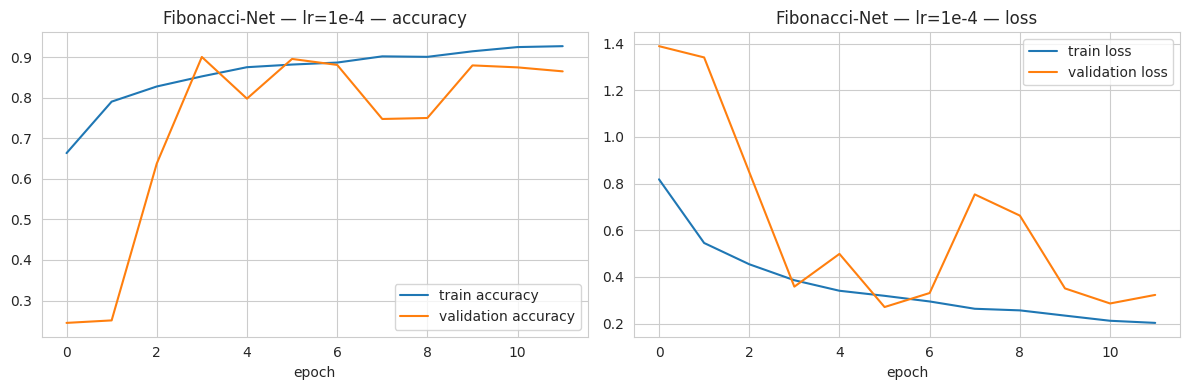

              precision    recall  f1-score   support

      glioma      0.916     0.840     0.877       300
  meningioma      0.743     0.605     0.667       306
     notumor      0.816     0.983     0.891       405
   pituitary      0.953     0.950     0.952       300

    accuracy                          0.854      1311
   macro avg      0.857     0.844     0.847      1311
weighted avg      0.853     0.854     0.849      1311

Recorded 'Fibonacci-Net | lr=0.0001': {'val_macro_f1': 0.8931, 'test_accuracy': 0.8543, 'test_macro_f1': 0.8465, 'recall_glioma': np.float64(0.84), 'params_M': 0.381, 'cpu_latency_ms': 72.9}


{'run': 'Fibonacci-Net | lr=0.0001',
 'model': 'Fibonacci-Net',
 'track': 'B',
 'config': 'lr=0.0001',
 'group': 'main',
 'val_accuracy': 0.8959608323133414,
 'val_macro_f1': 0.8931496772799531,
 'test_accuracy': 0.8543096872616324,
 'test_macro_f1': 0.8465379405110187,
 'recall_glioma': np.float64(0.84),
 'recall_meningioma': np.float64(0.6045751633986928),
 'recall_notumor': np.float64(0.9827160493827161),
 'recall_pituitary': np.float64(0.95),
 'params_M': 0.381,
 'size_MB': 4.8,
 'cpu_latency_ms': 72.9,
 'epochs': 12,
 'train_min': 16.7,
 'confusion_matrix': '[[252, 46, 2, 0], [19, 185, 88, 14], [2, 5, 398, 0], [2, 13, 0, 285]]',
 'model_path': '/content/drive/MyDrive/NeuroLens/models/Fibonacci-Net_lr=0.0001.keras'}

In [57]:
plot_training(history_fib_1em4, "Fibonacci-Net — lr=1e-4")
evaluate_and_record(fib_1em4_model, "Fibonacci-Net | lr=0.0001", "Fibonacci-Net", "B", "lr=0.0001", history_fib_1em4, fib_1em4_time)

#### Step 9 — Choose the best learning rate

The learning rate with the highest **validation** macro-F1 is used for the final comparison and for the ablation in 6.4.

In [58]:
display(show_results("Fibonacci-Net"))

best_fib_run = load_results().query("model == 'Fibonacci-Net'").sort_values("val_macro_f1", ascending=False).iloc[0]
BEST_FIB_LR = float(best_fib_run["config"].split("=")[1])
print("Best Fibonacci-Net learning rate:", BEST_FIB_LR)

,run,val_macro_f1,test_accuracy,test_macro_f1,recall_glioma,params_M,cpu_latency_ms,epochs
8,Fibonacci-Net | lr=0.001,0.958915,0.925248,0.923288,0.826667,0.381,75.0,15
9,Fibonacci-Net | lr=0.0003,0.965289,0.958047,0.957073,0.946667,0.381,74.5,15
10,Fibonacci-Net | lr=0.0001,0.893150,0.854310,0.846538,0.840000,0.381,72.9,12


Best Fibonacci-Net learning rate: 0.0003


### 6.4 Fibonacci-Net Ablation A — Avg-2Max replaced by max pooling

An **ablation** removes one component to measure how much it contributes. This network is identical to Fibonacci-Net except that the Avg-2Max pooling inside the two skip connections is replaced by ordinary max pooling. It is trained with the best learning rate from 6.3. If the full Fibonacci-Net scores clearly higher — especially on the smaller classes — the Avg-2Max design is contributing to performance.

#### Step 1 — The ablation architecture

Same as Fibonacci-Net; the only changes are the four `MaxPooling2D(3, 2)` layers in the skip connections (marked `# changed`).

In [59]:
def create_fibonacci_net_ablation_a():
    inputs = layers.Input(shape=IMG_SHAPE)

    # Block 1 (21 filters)
    x = layers.Conv2D(21, 3, padding="same")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D(2)(x)

    # Block 2 (34 filters)
    x = layers.Conv2D(34, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x2 = layers.ReLU()(x)
    x = layers.MaxPooling2D(2)(x2)

    # Block 3 (55 filters)
    x = layers.Conv2D(55, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x3 = layers.ReLU()(x)
    x = layers.MaxPooling2D(2)(x3)

    # Skip connection 1: block 2 -> block 4
    pcb1 = layers.Conv2D(24, 3, padding="same")(x2)
    pcb1 = layers.MaxPooling2D(3, 2, padding="same")(pcb1)          # changed
    pcb1 = layers.Conv2D(24, 3, padding="same")(pcb1)
    pcb1 = layers.MaxPooling2D(3, 2, padding="same")(pcb1)          # changed

    # Block 4 (89 filters) + skip connection 1
    x = layers.Conv2D(89, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.concatenate([x, layers.Resizing(14, 14)(pcb1)])

    # Skip connection 2: block 3 -> block 5
    pcb2 = layers.Conv2D(24, 3, padding="same")(x3)
    pcb2 = layers.MaxPooling2D(3, 2, padding="same")(pcb2)          # changed
    pcb2 = layers.Conv2D(24, 3, padding="same")(pcb2)
    pcb2 = layers.MaxPooling2D(3, 2, padding="same")(pcb2)          # changed

    # Block 5 (144 filters) + skip connection 2
    x = layers.Conv2D(144, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.concatenate([x, layers.Resizing(7, 7)(pcb2)])

    # Blocks 6 and 7 (depth-wise separable)
    x = DepthwiseSeparableConv(233)(x)
    x = DepthwiseSeparableConv(377)(x)

    # Classification head
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return Model(inputs, outputs, name="fibonacci_net_ablation_a")


ablation_model = create_fibonacci_net_ablation_a()
ablation_model.summary()

Model: "fibonacci_net_ablation_a"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_58 (Conv2D)  │ (None, 224, 224,  │        588 │ input_layer_6[0]… │
│                     │ 21)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 224, 224,  │         84 │ conv2d_58[0][0]   │
│ (BatchNormalizatio… │ 21)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_20 (ReLU)     │ (None, 224, 224,  │          0 │ batch_normalizat… │
│                     │ 21)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_56    │ (None, 112, 112,  │          0 │ re_lu_20[0][0]    │
│ (MaxPooling2D)      │ 21)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_59 (Conv2D)  │ (None, 112, 112,  │      6,460 │ max_pooling2d_56… │
│                     │ 34)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        136 │ conv2d_59[0][0]   │
│ (BatchNormalizatio… │ 34)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_21 (ReLU)     │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 34)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_57    │ (None, 56, 56,    │          0 │ re_lu_21[0][0]    │
│ (MaxPooling2D)      │ 34)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_60 (Conv2D)  │ (None, 56, 56,    │     16,885 │ max_pooling2d_57… │
│                     │ 55)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        220 │ conv2d_60[0][0]   │
│ (BatchNormalizatio… │ 55)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_22 (ReLU)     │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 55)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_58    │ (None, 28, 28,    │          0 │ re_lu_22[0][0]    │
│ (MaxPooling2D)      │ 55)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_61 (Conv2D)  │ (None, 112, 112,  │      7,368 │ re_lu_21[0][0]    │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_63 (Conv2D)  │ (None, 28, 28,    │     44,144 │ max_pooling2d_58… │
│                     │ 89)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_59    │ (None, 56, 56,    │          0 │ conv2d_61[0][0]   │
│ (MaxPooling2D)      │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │        356 │ conv2d_63[0][0] 

 Total params: 381,286 (1.45 MB)

 Trainable params: 379,380 (1.45 MB)

 Non-trainable params: 1,906 (7.45 KB)

#### Step 2 — Train with the best learning rate

In [60]:
set_seeds()
ablation_model.compile(optimizer=Adam(learning_rate=BEST_FIB_LR), loss="categorical_crossentropy", metrics=["accuracy"])

start = time.time()
history_ablation = ablation_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_SCRATCH,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
    ],
)
ablation_time = time.time() - start

Epoch 1/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 96s 540ms/step - accuracy: 0.7261 - loss: 0.6954 - val_accuracy: 0.2424 - val_loss: 1.3926 - learning_rate: 3.0000e-04
Epoch 2/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 81s 531ms/step - accuracy: 0.8335 - loss: 0.4536 - val_accuracy: 0.3647 - val_loss: 1.2890 - learning_rate: 3.0000e-04
Epoch 3/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 81s 529ms/step - accuracy: 0.8625 - loss: 0.3748 - val_accuracy: 0.6291 - val_loss: 0.8102 - learning_rate: 3.0000e-04
Epoch 4/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 81s 528ms/step - accuracy: 0.8697 - loss: 0.3440 - val_accuracy: 0.7087 - val_loss: 0.6947 - learning_rate: 3.0000e-04
Epoch 5/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 83s 543ms/step - accuracy: 0.8887 - loss: 0.3001 - val_accuracy: 0.8752 - val_loss: 0.3125 - learning_rate: 3.0000e-04
Epoch 6/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 81s 532ms/step - accuracy: 0.9011 - loss: 0.2662 - val_accuracy: 0.6756 - val_loss: 1.2966 - learning_rate: 3.0000e-04
Epoch 7/15
153/153 ━━━━━━━━━━━━━━━━━━━━ 81s 52

#### Step 3 — Evaluate and record, then compare with the full Fibonacci-Net

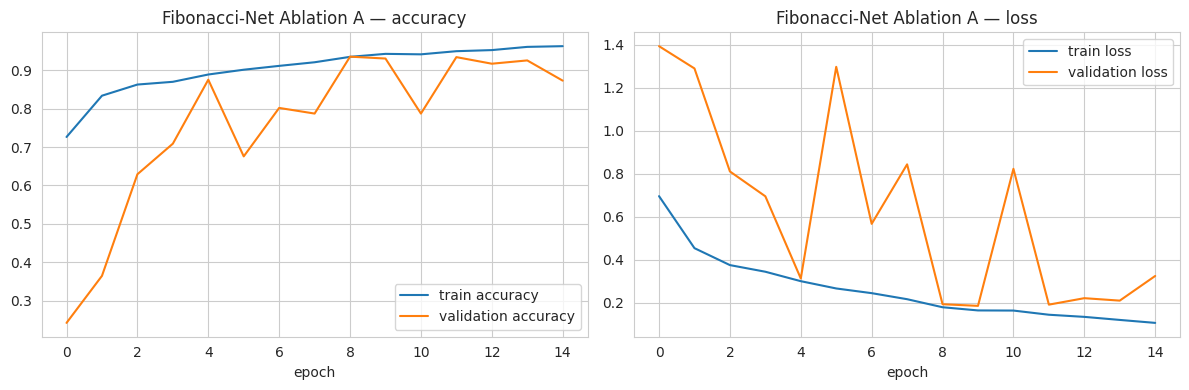

              precision    recall  f1-score   support

      glioma      0.935     0.860     0.896       300
  meningioma      0.864     0.807     0.834       306
     notumor      0.885     0.985     0.932       405
   pituitary      0.980     0.973     0.977       300

    accuracy                          0.912      1311
   macro avg      0.916     0.906     0.910      1311
weighted avg      0.913     0.912     0.911      1311

Recorded 'Fibonacci-Net Ablation A | lr=0.0003': {'val_macro_f1': 0.9295, 'test_accuracy': 0.9123, 'test_macro_f1': 0.9098, 'recall_glioma': np.float64(0.86), 'params_M': 0.381, 'cpu_latency_ms': 68.1}


{'run': 'Fibonacci-Net Ablation A | lr=0.0003',
 'model': 'Fibonacci-Net Ablation A',
 'track': 'B',
 'config': 'lr=0.0003',
 'group': 'ablation',
 'val_accuracy': 0.9302325581395349,
 'val_macro_f1': 0.9295213993939392,
 'test_accuracy': 0.9122807017543859,
 'test_macro_f1': 0.909781103052385,
 'recall_glioma': np.float64(0.86),
 'recall_meningioma': np.float64(0.8071895424836601),
 'recall_notumor': np.float64(0.9851851851851852),
 'recall_pituitary': np.float64(0.9733333333333334),
 'params_M': 0.381,
 'size_MB': 4.7,
 'cpu_latency_ms': 68.1,
 'epochs': 15,
 'train_min': 20.6,
 'confusion_matrix': '[[258, 35, 6, 1], [11, 247, 43, 5], [5, 1, 399, 0], [2, 3, 3, 292]]',
 'model_path': '/content/drive/MyDrive/NeuroLens/models/Fibonacci-Net_Ablation_A_lr=0.0003.keras'}

In [61]:
plot_training(history_ablation, "Fibonacci-Net Ablation A")
evaluate_and_record(ablation_model, f"Fibonacci-Net Ablation A | lr={BEST_FIB_LR:g}", "Fibonacci-Net Ablation A", "B",
                    f"lr={BEST_FIB_LR:g}", history_ablation, ablation_time, group="ablation")

In [62]:
pd.concat([show_results("Fibonacci-Net"), show_results("Fibonacci-Net Ablation A")])

,run,val_macro_f1,test_accuracy,test_macro_f1,recall_glioma,params_M,cpu_latency_ms,epochs
8,Fibonacci-Net | lr=0.001,0.958915,0.925248,0.923288,0.826667,0.381,75.0,15
9,Fibonacci-Net | lr=0.0003,0.965289,0.958047,0.957073,0.946667,0.381,74.5,15
10,Fibonacci-Net | lr=0.0001,0.893150,0.854310,0.846538,0.840000,0.381,72.9,12
11,Fibonacci-Net Ablation A | lr=0.0003,0.929521,0.912281,0.909781,0.860000,0.381,68.1,15


## 7. Comparison and model selection

This section only reads `results.csv`, so it can be run at any time — even in a fresh Colab session after running Section 1.

### 7.1 S1 vs. S2 for each pretrained model (validation macro-F1)

Whether fine-tuning the top 20 layers (S2) improves on training the head alone (S1), for each pretrained backbone. The better stage per backbone (by validation macro-F1) is carried into the final comparison.

In [63]:
results = load_results()
track_a = results[results["track"] == "A"]
stage_table = track_a.pivot_table(index="model", columns="config", values="val_macro_f1")
stage_table["best stage"] = stage_table.idxmax(axis=1)
stage_table.round(4)

config,S1,S2,best stage
model,,,
EfficientNetB0,0.8998,0.9212,S2
MobileNetV2,0.9088,0.9285,S2
Xception,0.8806,0.9245,S2


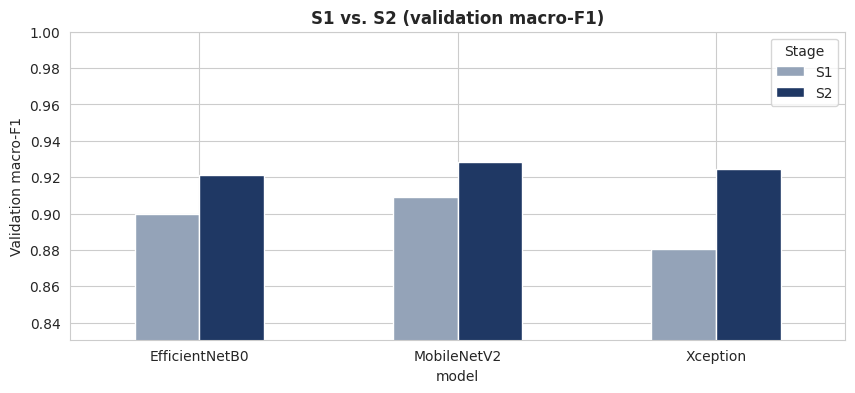

In [64]:
stage_table.drop(columns="best stage").plot(kind="bar", figsize=(10, 4), rot=0,
                                               color=["#94a3b8", "#1f3864"])
plt.ylabel("Validation macro-F1")
plt.ylim(max(0, stage_table.drop(columns="best stage").min().min() - 0.05), 1.0)
plt.title("S1 vs. S2 (validation macro-F1)", fontweight="bold")
plt.legend(title="Stage")
plt.show()

### 7.2 Final comparison on the test set

One row per model: its best configuration (chosen on validation macro-F1). Ablation runs are listed separately in 7.3.

In [65]:
main = results[results["group"] == "main"]
best_configs = (main.sort_values("val_macro_f1", ascending=False)
                    .groupby("model", as_index=False).first()
                    .sort_values("test_macro_f1", ascending=False)
                    .reset_index(drop=True))

final_cols = ["model", "track", "config", "test_accuracy", "test_macro_f1", "recall_glioma",
              "params_M", "size_MB", "cpu_latency_ms"]
final_table = best_configs[final_cols]
final_table.to_csv(os.path.join(OUTPUT_DIR, "final_comparison.csv"), index=False)
final_table.style.format({"test_accuracy": "{:.4f}", "test_macro_f1": "{:.4f}", "recall_glioma": "{:.4f}"})

,model,track,config,test_accuracy,test_macro_f1,recall_glioma,params_M,size_MB,cpu_latency_ms
0,Fibonacci-Net,B,lr=0.0003,0.9580,0.9571,0.9467,0.381000,4.800000,74.500000
1,MobileNetV2,A,S2,0.9161,0.9121,0.8533,2.587000,23.100000,188.900000
2,EfficientNetB0,A,S2,0.9130,0.9081,0.8533,4.379000,31.700000,341.300000
3,Xception,A,S2,0.8924,0.8876,0.8833,21.387000,148.800000,280.800000
4,Custom CNN,B,tuned,0.8215,0.8108,0.7067,9.861000,118.400000,51.000000


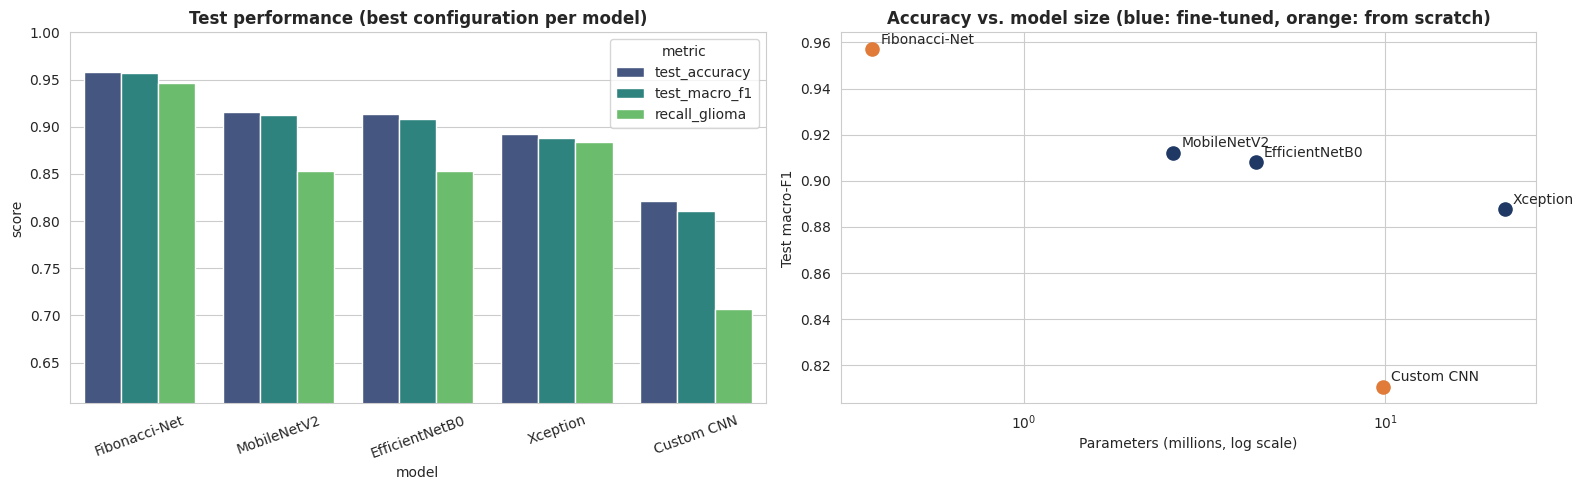

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

plot_df = final_table.melt(id_vars="model", value_vars=["test_accuracy", "test_macro_f1", "recall_glioma"],
                           var_name="metric", value_name="score")
sns.barplot(data=plot_df, x="model", y="score", hue="metric", palette="viridis", ax=axes[0])
axes[0].set_ylim(max(0, plot_df["score"].min() - 0.1), 1.0)
axes[0].set_title("Test performance (best configuration per model)", fontweight="bold")
axes[0].tick_params(axis="x", rotation=20)

colors = {"A": "#1f3864", "B": "#e07b39"}
for _, r in final_table.iterrows():
    axes[1].scatter(r["params_M"], r["test_macro_f1"], s=90, color=colors[r["track"]])
    axes[1].annotate(r["model"], (r["params_M"], r["test_macro_f1"]), xytext=(6, 4), textcoords="offset points")
axes[1].set_xscale("log")
axes[1].set_xlabel("Parameters (millions, log scale)")
axes[1].set_ylabel("Test macro-F1")
axes[1].set_title("Accuracy vs. model size (blue: fine-tuned, orange: from scratch)", fontweight="bold")

plt.tight_layout()
plt.show()

### 7.3 Ablation result

Contribution of Avg-2Max pooling: full Fibonacci-Net (best learning rate) vs. Ablation A (same learning rate, max pooling instead).

In [67]:
fib_best = results[(results["model"] == "Fibonacci-Net") & (results["config"] == f"lr={BEST_FIB_LR:g}")]
ablation = results[results["model"] == "Fibonacci-Net Ablation A"]
recall_cols = [f"recall_{c}" for c in CLASS_NAMES]
ablation_table = pd.concat([fib_best, ablation])[["model", "config", "test_accuracy", "test_macro_f1"] + recall_cols]
ablation_table.round(4)

,model,config,test_accuracy,test_macro_f1,recall_glioma,recall_meningioma,recall_notumor,recall_pituitary
9,Fibonacci-Net,lr=0.0003,0.9580,0.9571,0.9467,0.9183,0.9753,0.9867
11,Fibonacci-Net Ablation A,lr=0.0003,0.9123,0.9098,0.8600,0.8072,0.9852,0.9733


### 7.4 Confusion matrices of the two best models

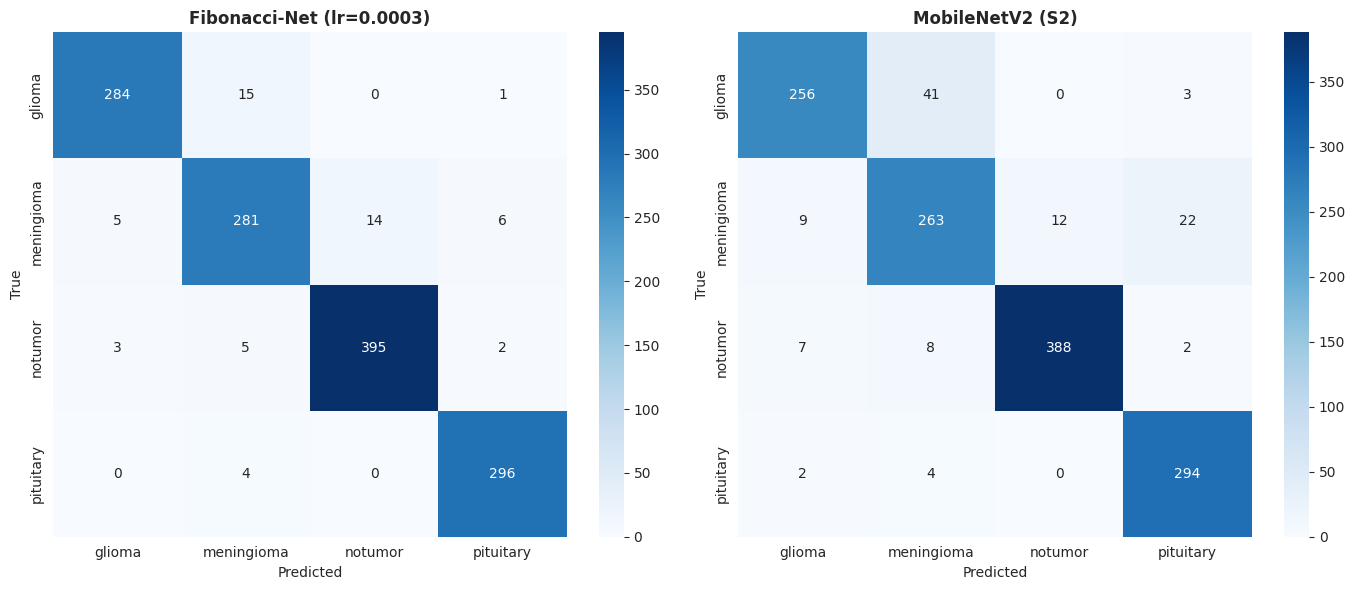

In [68]:
top2 = final_table.head(2)
fig, axes = plt.subplots(1, len(top2), figsize=(7 * len(top2), 6))
axes = np.atleast_1d(axes)
for ax, (_, r) in zip(axes, top2.iterrows()):
    cm = np.array(json.loads(results[(results["model"] == r["model"]) & (results["config"] == r["config"])]
                             ["confusion_matrix"].iloc[0]))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_title(f"{r['model']} ({r['config']})", fontweight="bold")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
plt.tight_layout()
plt.show()

### 7.5 Model selection (decision rule)

**Step 1 — the comparison rule** (fixed in the project proposal before seeing the results):
1. Find the model with the highest test macro-F1.
2. Every model within **1 percentage point** of it is treated as equally accurate.
3. Among those, the **smallest** model (fewest parameters, then lowest CPU latency) wins.

**Step 2 — the deployed model.** NeuroLens deploys **Fibonacci-Net** (`DEPLOY_MODEL`), in the learning-rate configuration with the best validation macro-F1 (Section 6.3, Step 9). The reasons are part of the project's design: it is a lightweight architecture trained entirely on this dataset (no ImageNet weights), it is small and fast enough for CPU inference in the web app, and its own convolutional layers give the heatmaps and embeddings used for explanation and similar-case search.

The cell prints both: what the comparison rule picks, and how Fibonacci-Net compares with it — so the report states the accuracy–efficiency trade-off honestly. Set `DEPLOY_MODEL = None` to deploy whatever the comparison rule picks instead.

In [69]:
MARGIN = 0.01
DEPLOY_MODEL = "Fibonacci-Net"      # None = deploy the model chosen by the comparison rule

best = final_table.iloc[0]
comparable = final_table[final_table["test_macro_f1"] >= best["test_macro_f1"] - MARGIN]
rule_choice = comparable.sort_values(["params_M", "cpu_latency_ms"]).iloc[0]

print(f"Highest test macro-F1: {best['model']} ({best['config']}) = {best['test_macro_f1']:.4f}")
print(f"Models within {MARGIN * 100:.0f} percentage point: {', '.join(comparable['model'])}")
print(f"Comparison rule picks: {rule_choice['model']} ({rule_choice['config']})")

if DEPLOY_MODEL:
    if DEPLOY_MODEL not in set(final_table["model"]):
        raise ValueError(f"{DEPLOY_MODEL} has no results yet — run its section first.")
    selected = final_table[final_table["model"] == DEPLOY_MODEL].iloc[0]
else:
    selected = rule_choice

print(f"\nSELECTED FOR DEPLOYMENT: {selected['model']} ({selected['config']})")
print(f"  test macro-F1 {selected['test_macro_f1']:.4f} | test accuracy {selected['test_accuracy']:.4f} | "
      f"glioma recall {selected['recall_glioma']:.4f} | {selected['params_M']:.2f}M parameters | "
      f"{selected['cpu_latency_ms']:.1f} ms per image on CPU")
if selected["model"] == rule_choice["model"]:
    print("  -> this is also the model the comparison rule picks.")
else:
    gap = (best["test_macro_f1"] - selected["test_macro_f1"]) * 100
    print(f"  -> compared with the most accurate model, {best['model']}: macro-F1 {gap:.2f} points lower, "
          f"{best['params_M'] / selected['params_M']:.1f}x fewer parameters, "
          f"{best['cpu_latency_ms'] / selected['cpu_latency_ms']:.1f}x faster on CPU.")
    if gap > 3:
        print("  -> the gap is large: consider a full run (QUICK_RUN = False) before deploying, and discuss it in the report.")

Highest test macro-F1: Fibonacci-Net (lr=0.0003) = 0.9571
Models within 1 percentage point: Fibonacci-Net
Comparison rule picks: Fibonacci-Net (lr=0.0003)

SELECTED FOR DEPLOYMENT: Fibonacci-Net (lr=0.0003)
  test macro-F1 0.9571 | test accuracy 0.9580 | glioma recall 0.9467 | 0.38M parameters | 74.5 ms per image on CPU
  -> this is also the model the comparison rule picks.


### 7.6 Export the selected model

The selected model and its class names are copied to `OUTPUT_DIR/selected/` for the Grad-CAM notebook and the dashboard. Every model expects an RGB image resized to 224 × 224 with pixels scaled to [0, 1]; any backbone-specific scaling is built into the model.

In [70]:
import shutil

SELECTED_DIR = os.path.join(OUTPUT_DIR, "selected")
os.makedirs(SELECTED_DIR, exist_ok=True)
selected_path = results[(results["model"] == selected["model"]) & (results["config"] == selected["config"])]["model_path"].iloc[0]
shutil.copy(selected_path, os.path.join(SELECTED_DIR, "brain_tumor_model.keras"))

with open(os.path.join(SELECTED_DIR, "model_info.json"), "w") as f:
    json.dump({
        "model": selected["model"], "config": selected["config"], "class_names": CLASS_NAMES,
        "input_size": list(IMG_SIZE), "input_scaling": "RGB, pixels / 255",
        "test_macro_f1": float(selected["test_macro_f1"]), "test_accuracy": float(selected["test_accuracy"]),
        "test_glioma_recall": float(selected["recall_glioma"]),
        "chosen_by": "deployment choice (DEPLOY_MODEL)" if DEPLOY_MODEL else "comparison rule",
        "comparison_rule_pick": f"{rule_choice['model']} ({rule_choice['config']})",
        "training_run": "quick" if QUICK_RUN else "full",
    }, f, indent=2)
print("Exported to", SELECTED_DIR, ":", os.listdir(SELECTED_DIR))

Exported to /content/drive/MyDrive/NeuroLens/selected : ['brain_tumor_model.keras', 'model_info.json']


## 8. Explainability — choosing the CAM method

A heatmap is only useful if it shows what the model **actually** relied on. Grad-CAM is the most widely used method, but several later variants claim better localisation or faithfulness. This section compares five class-activation-mapping (CAM) methods on the **selected model** and chooses one with a rule fixed in advance.

| Method | How the map is formed | Cost per image |
|---|---|---|
| **Grad-CAM** (Selvaraju et al. 2017) | channel weights = average gradient of the class score | 1 forward + 1 backward pass |
| **Grad-CAM++** (Chattopadhay et al. 2018) | weighted positive higher-order gradients — better coverage of large / multiple regions | 1 forward + 1 backward pass |
| **Score-CAM** (Wang et al. 2020) | gradient-free: each activation map is used as a mask and weighted by the score it produces | one forward pass per channel |
| **Layer-CAM** (Jiang et al. 2021) | element-wise positive gradients × activations — finer detail | 1 forward + 1 backward pass |
| **Eigen-CAM** (Muhammad & Yeasin 2020) | first principal component of the activations — gradient-free but **class-agnostic** | 1 forward pass + SVD |

**How they are compared** (on correctly classified test images, stratified by class):

| Test | Meaning | Better |
|---|---|---|
| **Deletion AUC** | remove pixels in order of importance and track the class probability — a faithful map makes it drop quickly | lower |
| **Insertion AUC** | reveal pixels on a blurred image in order of importance — a faithful map makes the probability rise quickly | higher |
| **Faithful-case rate** | share of images where the method's deletion curve falls clearly faster than removing pixels in random order | higher |
| **Sanity check** (Adebayo et al. 2018) | the maps should change when the model's weights are randomised; a method whose maps barely change is not explaining the model | must pass |
| **CPU time** | time per explanation on a CPU, as in the deployed dashboard | ≤ 1 s to be deployable |

**Decision rule** (fixed before seeing results): among methods that pass the sanity check and run in ≤ 1 s on CPU, choose the one with the best combined score (insertion AUC − deletion AUC). A more faithful but slower method is reported as an offline option.

*If this runs in a new Colab session: run Sections 1–4 first, and the Fibonacci-Net custom-layer cell (Section 6.3, Step 1) if the selected model is Fibonacci-Net.*

### 8.1 Settings and the selected model

The selected model is loaded from the file exported in Section 7.6, so this section does not depend on variables from earlier sections.

In [71]:
from scipy.stats import spearmanr

CAM_SAMPLES_PER_CLASS = 25      # correctly classified test images per class used for the comparison
CAM_STEPS = 20                  # deletion / insertion curve resolution (5% of the pixels per step)
SCORECAM_MAX_CHANNELS = 256     # Score-CAM uses the most active channels (one forward pass each) to keep it affordable
SANITY_SAMPLES = 12             # images used for the weight-randomisation sanity check
CPU_TIME_LIMIT_MS = 1000        # deployable if an explanation takes at most 1 s on CPU
FAITHFUL_MARGIN = 0.05          # "clearly faster" than random deletion = lower deletion AUC by at least 0.05

cam_model = tf.keras.models.load_model(os.path.join(OUTPUT_DIR, "selected", "brain_tumor_model.keras"), compile=False)
with open(os.path.join(OUTPUT_DIR, "selected", "model_info.json")) as f:
    selected_info = json.load(f)
print("Selected model:", selected_info["model"], selected_info["config"])

Selected model: Fibonacci-Net lr=0.0003


### 8.2 Target layer and activations

All five methods explain the **same layer**: the last convolutional block of the selected model, so the comparison reflects the method and not the layer.

- For **Fibonacci-Net / the custom CNN**, that is the last convolutional layer in the model itself.
- For a **pretrained model**, the backbone is a nested sub-model; its output (the last convolutional block) is used, and the layers are run one after another so the gradients can reach it.

`activations_and_gradients` returns the layer's activations, the gradient of the class score with respect to them, and the predicted probabilities. Every gradient-based method below uses it.

In [72]:
def find_target_layer(model):
    for layer in reversed(model.layers):
        if isinstance(layer, tf.keras.Model):
            return layer.name                                   # nested pretrained backbone
        if "depthwise_separable_conv" in layer.name or isinstance(layer, tf.keras.layers.Conv2D):
            return layer.name
    raise ValueError("No convolutional layer found")


def activations_and_gradients(model, x, class_index, layer_name):
    """Returns (activations [h, w, k], gradients [h, w, k], probabilities [classes]) for one image batch of size 1."""
    target = model.get_layer(layer_name)
    x = tf.convert_to_tensor(x, dtype=tf.float32)
    with tf.GradientTape() as tape:
        if isinstance(target, tf.keras.Model):
            h, acts = x, None
            for layer in model.layers:
                if isinstance(layer, tf.keras.layers.InputLayer):
                    continue
                h = layer(h, training=False)
                if layer is target:
                    acts = h
                    tape.watch(acts)
            probs = h
        else:
            grad_model = tf.keras.models.Model(model.input, [target.output, model.output])
            acts, probs = grad_model(x, training=False)
        score = probs[:, class_index]
    grads = tape.gradient(score, acts)
    return acts[0].numpy(), grads[0].numpy(), probs[0].numpy()


def normalise_map(cam):
    """ReLU, scale to [0, 1] and resize to the input size."""
    cam = np.maximum(cam, 0)
    cam = cam / cam.max() if cam.max() > 0 else cam
    return tf.image.resize(cam[..., None], IMG_SIZE, method="bilinear").numpy()[..., 0]


CAM_LAYER = find_target_layer(cam_model)
print("Target layer:", CAM_LAYER)

Target layer: depthwise_separable_conv_5


### 8.3 The five CAM methods

Each method is written out separately so the differences are easy to see. Every function takes one preprocessed image `x` of shape (1, 224, 224, 3) and the class index to explain, and returns a 224 × 224 map with values 0–1.

#### Grad-CAM

In [73]:
def grad_cam(model, x, class_index):
    acts, grads, _ = activations_and_gradients(model, x, class_index, CAM_LAYER)
    weights = grads.mean(axis=(0, 1))                            # one weight per channel
    return normalise_map((acts * weights).sum(axis=-1))

#### Grad-CAM++

Uses the closed-form weights of Chattopadhay et al. (2018): positive gradients are weighted by α, computed from the second- and third-order terms (with the exponential of the class score, these become powers of the first gradient).

In [74]:
def grad_cam_plus_plus(model, x, class_index):
    acts, grads, _ = activations_and_gradients(model, x, class_index, CAM_LAYER)
    g2, g3 = grads ** 2, grads ** 3
    denominator = 2 * g2 + acts.sum(axis=(0, 1)) * g3
    alpha = g2 / np.where(denominator != 0, denominator, 1e-8)
    weights = (alpha * np.maximum(grads, 0)).sum(axis=(0, 1))
    return normalise_map((acts * weights).sum(axis=-1))

#### Score-CAM

Gradient-free. Each activation map is upsampled, scaled to 0–1 and used as a mask on the input; the class probability of the masked image becomes that channel's weight. The `SCORECAM_MAX_CHANNELS` most active channels are used (one forward pass each, in batches).

In [75]:
def score_cam(model, x, class_index, batch_size=64):
    acts, _, _ = activations_and_gradients(model, x, class_index, CAM_LAYER)
    channels = np.argsort(acts.mean(axis=(0, 1)))[::-1][:SCORECAM_MAX_CHANNELS]
    maps = tf.image.resize(acts[..., channels], IMG_SIZE, method="bilinear").numpy()          # 224 x 224 x c
    mins, maxs = maps.min(axis=(0, 1)), maps.max(axis=(0, 1))
    masks = (maps - mins) / np.where(maxs - mins > 0, maxs - mins, 1)
    weights = []
    for start in range(0, len(channels), batch_size):
        m = np.moveaxis(masks[..., start:start + batch_size], -1, 0)[..., None]             # b x 224 x 224 x 1
        weights.append(model.predict(x * m, verbose=0)[:, class_index])
    weights = np.concatenate(weights)
    return normalise_map((acts[..., channels] * weights).sum(axis=-1))

#### Layer-CAM

Weights every activation **element** by its own positive gradient, instead of one weight per channel.

In [76]:
def layer_cam(model, x, class_index):
    acts, grads, _ = activations_and_gradients(model, x, class_index, CAM_LAYER)
    return normalise_map((np.maximum(grads, 0) * acts).sum(axis=-1))

#### Eigen-CAM

Projects the activations onto their first principal component. It needs no gradients, but it is **class-agnostic**: it shows the same map whatever class is being explained — a useful reference point.

In [77]:
def eigen_cam(model, x, class_index):
    acts, _, _ = activations_and_gradients(model, x, class_index, CAM_LAYER)
    h, w, k = acts.shape
    flat = acts.reshape(-1, k)
    flat = flat - flat.mean(axis=0)
    _, _, vt = np.linalg.svd(flat, full_matrices=False)
    projection = (flat @ vt[0]).reshape(h, w)
    if projection.sum() < 0:                                      # the sign of a principal component is arbitrary
        projection = -projection
    return normalise_map(projection)


CAM_METHODS = {
    "Grad-CAM": grad_cam,
    "Grad-CAM++": grad_cam_plus_plus,
    "Score-CAM": score_cam,
    "Layer-CAM": layer_cam,
    "Eigen-CAM": eigen_cam,
}

### 8.4 Choose the evaluation images

Only **correctly classified** test images are used: explaining a wrong prediction mixes two questions (is the model wrong, or is the explanation wrong?). `CAM_SAMPLES_PER_CLASS` images are drawn from each class with a fixed seed.

In [78]:
def load_image(path):
    image = Image.open(path).convert("RGB").resize(IMG_SIZE)
    return np.asarray(image, dtype="float32")[None] / 255.0     # (1, 224, 224, 3), same scaling as the generators


test_gen.reset()
test_probs = cam_model.predict(test_gen, verbose=0)
test_eval = pd.DataFrame({"image_path": test_gen.filenames, "true_idx": test_gen.classes})
test_eval["label"] = [CLASS_NAMES[i] for i in test_eval["true_idx"]]
test_eval["pred_idx"] = test_probs.argmax(axis=1)
correct = test_eval[test_eval["true_idx"] == test_eval["pred_idx"]]

cam_sample = (correct.groupby("label", group_keys=False)
              .apply(lambda g: g.sample(min(len(g), CAM_SAMPLES_PER_CLASS), random_state=SEED))
              .reset_index(drop=True))
print(f"{len(cam_sample)} correctly classified test images:")
print(cam_sample["label"].value_counts().reindex(CLASS_NAMES))

100 correctly classified test images:
label
glioma        25
meningioma    25
notumor       25
pituitary     25
Name: count, dtype: int64


### 8.5 Deletion and insertion tests

For each image and method, pixels are ranked by the heatmap (most important first).

- **Deletion:** the top-ranked pixels are set to black (the MRI background) in `CAM_STEPS` steps; the area under the class-probability curve is recorded — **lower** means the map found the pixels the model depends on.
- **Insertion:** starting from a heavily blurred image, the top-ranked pixels are revealed step by step; **higher** area means the map found the pixels that carry the evidence.
- **Random baseline:** the same deletion test with pixels removed in a random order (the same random order for every method). The **faithful-case rate** is the share of images where the method's deletion AUC is at least `FAITHFUL_MARGIN` lower than random.

The areas are the mean probability over the curve, so they lie between 0 and 1.

In [79]:
def blurred(x):
    small = tf.image.resize(x, (IMG_SIZE[0] // 16, IMG_SIZE[1] // 16), method="area")
    return tf.image.resize(small, IMG_SIZE, method="bilinear").numpy()


def curve_auc(model, x, class_index, order, mode):
    """Area under the deletion or insertion curve for a given pixel order (indices of flattened pixels)."""
    n_pixels = order.size
    start = x.copy() if mode == "deletion" else blurred(x)
    finish = np.zeros_like(x) if mode == "deletion" else x.copy()
    batch = []
    for step in range(CAM_STEPS + 1):
        image = start.copy().reshape(-1, 3)
        chosen = order[: int(n_pixels * step / CAM_STEPS)]
        image[chosen] = finish.reshape(-1, 3)[chosen]
        batch.append(image.reshape(x.shape[1:]))
    probs = model.predict(np.stack(batch), verbose=0)[:, class_index]
    return float(np.trapezoid(probs, dx=1 / CAM_STEPS)) if hasattr(np, "trapezoid") else float(np.trapz(probs, dx=1 / CAM_STEPS))


rng = np.random.default_rng(SEED)
random_order = rng.permutation(IMG_SIZE[0] * IMG_SIZE[1])       # shared by all methods

cam_rows, example_maps = [], {}
start_all = time.time()
for i, row in cam_sample.iterrows():
    x = load_image(row["image_path"])
    class_index = int(row["true_idx"])
    random_deletion = curve_auc(cam_model, x, class_index, random_order, "deletion")
    for method, fn in CAM_METHODS.items():
        cam = fn(cam_model, x, class_index)
        order = np.argsort(cam.ravel())[::-1]                    # most important pixels first
        deletion = curve_auc(cam_model, x, class_index, order, "deletion")
        insertion = curve_auc(cam_model, x, class_index, order, "insertion")
        cam_rows.append({"image": i, "label": row["label"], "method": method, "deletion_auc": deletion,
                         "insertion_auc": insertion, "random_deletion_auc": random_deletion,
                         "faithful": deletion <= random_deletion - FAITHFUL_MARGIN})
        if row["label"] not in example_maps or len(example_maps[row["label"]]["maps"]) < len(CAM_METHODS):
            example_maps.setdefault(row["label"], {"image": x[0], "maps": {}})["maps"][method] = cam
    if (i + 1) % 20 == 0:
        print(f"  {i + 1}/{len(cam_sample)} images done ({(time.time() - start_all) / 60:.1f} min)")

cam_results = pd.DataFrame(cam_rows)
cam_results.to_csv(os.path.join(OUTPUT_DIR, "cam_per_image.csv"), index=False)
print(f"Finished in {(time.time() - start_all) / 60:.1f} min")

  20/100 images done (1.2 min)
  40/100 images done (2.4 min)
  60/100 images done (3.5 min)
  80/100 images done (4.7 min)
  100/100 images done (5.8 min)
Finished in 5.8 min


### 8.6 Sanity check — do the maps depend on the trained weights?

A copy of the model with **randomly re-initialised weights** is explained on a few images. For each method, the rank correlation (Spearman) between the heatmap of the trained model and that of the random model is measured. A faithful method must produce **different** maps once the model knows nothing, so the method **passes** if the mean correlation is below 0.5 (a blank map from the random model counts as a correlation of 0).

In [80]:
random_model = tf.keras.models.clone_model(cam_model)            # same architecture, fresh random weights
sanity_images = cam_sample.sample(min(SANITY_SAMPLES, len(cam_sample)), random_state=SEED)

sanity = {}
for method, fn in CAM_METHODS.items():
    correlations = []
    for _, row in sanity_images.iterrows():
        x = load_image(row["image_path"])
        trained_map = fn(cam_model, x, int(row["true_idx"]))
        random_map = fn(random_model, x, int(row["true_idx"]))
        if trained_map.std() > 0 and random_map.std() > 0:
            correlations.append(spearmanr(trained_map.ravel(), random_map.ravel()).correlation)
        else:
            correlations.append(0.0)                              # one map is blank, so the two maps share nothing
    sanity[method] = float(np.nanmean(correlations)) if correlations else float("nan")

pd.Series(sanity, name="rank correlation with random-weight model").round(3)

,rank correlation with random-weight model
Grad-CAM,0.233
Grad-CAM++,0.683
Score-CAM,0.776
Layer-CAM,0.683
Eigen-CAM,0.156


### 8.7 CPU time per explanation

The dashboard runs on a CPU, so the time to explain one image is measured on the CPU (median of 3 runs, after one warm-up run).

In [81]:
cpu_ms = {}
timing_image = load_image(cam_sample["image_path"].iloc[0])
timing_class = int(cam_sample["true_idx"].iloc[0])
with tf.device("/CPU:0"):
    cpu_model = tf.keras.models.clone_model(cam_model)
    cpu_model.set_weights(cam_model.get_weights())
    for method, fn in CAM_METHODS.items():
        fn(cpu_model, timing_image, timing_class)                # warm-up
        times = []
        for _ in range(3):
            t0 = time.perf_counter()
            fn(cpu_model, timing_image, timing_class)
            times.append((time.perf_counter() - t0) * 1000)
        cpu_ms[method] = float(np.median(times))

pd.Series(cpu_ms, name="CPU ms per explanation").round(0)

,CPU ms per explanation
Grad-CAM,200.0
Grad-CAM++,204.0
Score-CAM,11359.0
Layer-CAM,274.0
Eigen-CAM,240.0


### 8.8 Results table

In [82]:
cam_table = (cam_results.groupby("method")
             .agg(deletion_auc=("deletion_auc", "mean"), insertion_auc=("insertion_auc", "mean"),
                  faithful_case_rate=("faithful", "mean"))
             .reindex(CAM_METHODS.keys()))
cam_table["random_deletion_auc"] = cam_results["random_deletion_auc"].mean()
cam_table["combined_score"] = cam_table["insertion_auc"] - cam_table["deletion_auc"]
cam_table["sanity_correlation"] = pd.Series(sanity)
cam_table["sanity_pass"] = cam_table["sanity_correlation"] < 0.5
cam_table["cpu_ms"] = pd.Series(cpu_ms)
cam_table["deployable"] = cam_table["sanity_pass"] & (cam_table["cpu_ms"] <= CPU_TIME_LIMIT_MS)
cam_table = cam_table.sort_values("combined_score", ascending=False)
cam_table.to_csv(os.path.join(OUTPUT_DIR, "cam_comparison.csv"))
cam_table.round(3)

,deletion_auc,insertion_auc,faithful_case_rate,random_deletion_auc,combined_score,sanity_correlation,sanity_pass,cpu_ms,deployable
method,,,,,,,,,
Score-CAM,0.400,0.723,0.25,0.274,0.323,0.776,False,11359.010,False
Grad-CAM++,0.414,0.724,0.25,0.274,0.310,0.683,False,204.131,False
Layer-CAM,0.414,0.724,0.25,0.274,0.310,0.683,False,274.395,False
Grad-CAM,0.415,0.722,0.25,0.274,0.306,0.233,True,200.425,True
Eigen-CAM,0.537,0.640,0.25,0.274,0.103,0.156,True,240.448,True


Per-class view — whether a method works equally well for every tumor type (combined score = insertion − deletion):

In [83]:
per_class = (cam_results.assign(combined=cam_results["insertion_auc"] - cam_results["deletion_auc"])
             .pivot_table(index="method", columns="label", values="combined", aggfunc="mean")
             .reindex(index=list(CAM_METHODS), columns=CLASS_NAMES))
per_class.round(3)

label,glioma,meningioma,notumor,pituitary
method,,,,
Grad-CAM,0.008,0.498,0.264,0.455
Grad-CAM++,0.033,0.540,0.245,0.423
Score-CAM,0.065,0.547,0.236,0.445
Layer-CAM,0.033,0.540,0.245,0.423
Eigen-CAM,-0.254,0.284,0.095,0.288


### 8.9 Visual comparison

One correctly classified image per class, with the heatmap of every method. The numbers only tell part of the story — a good method should also highlight a plausible region.

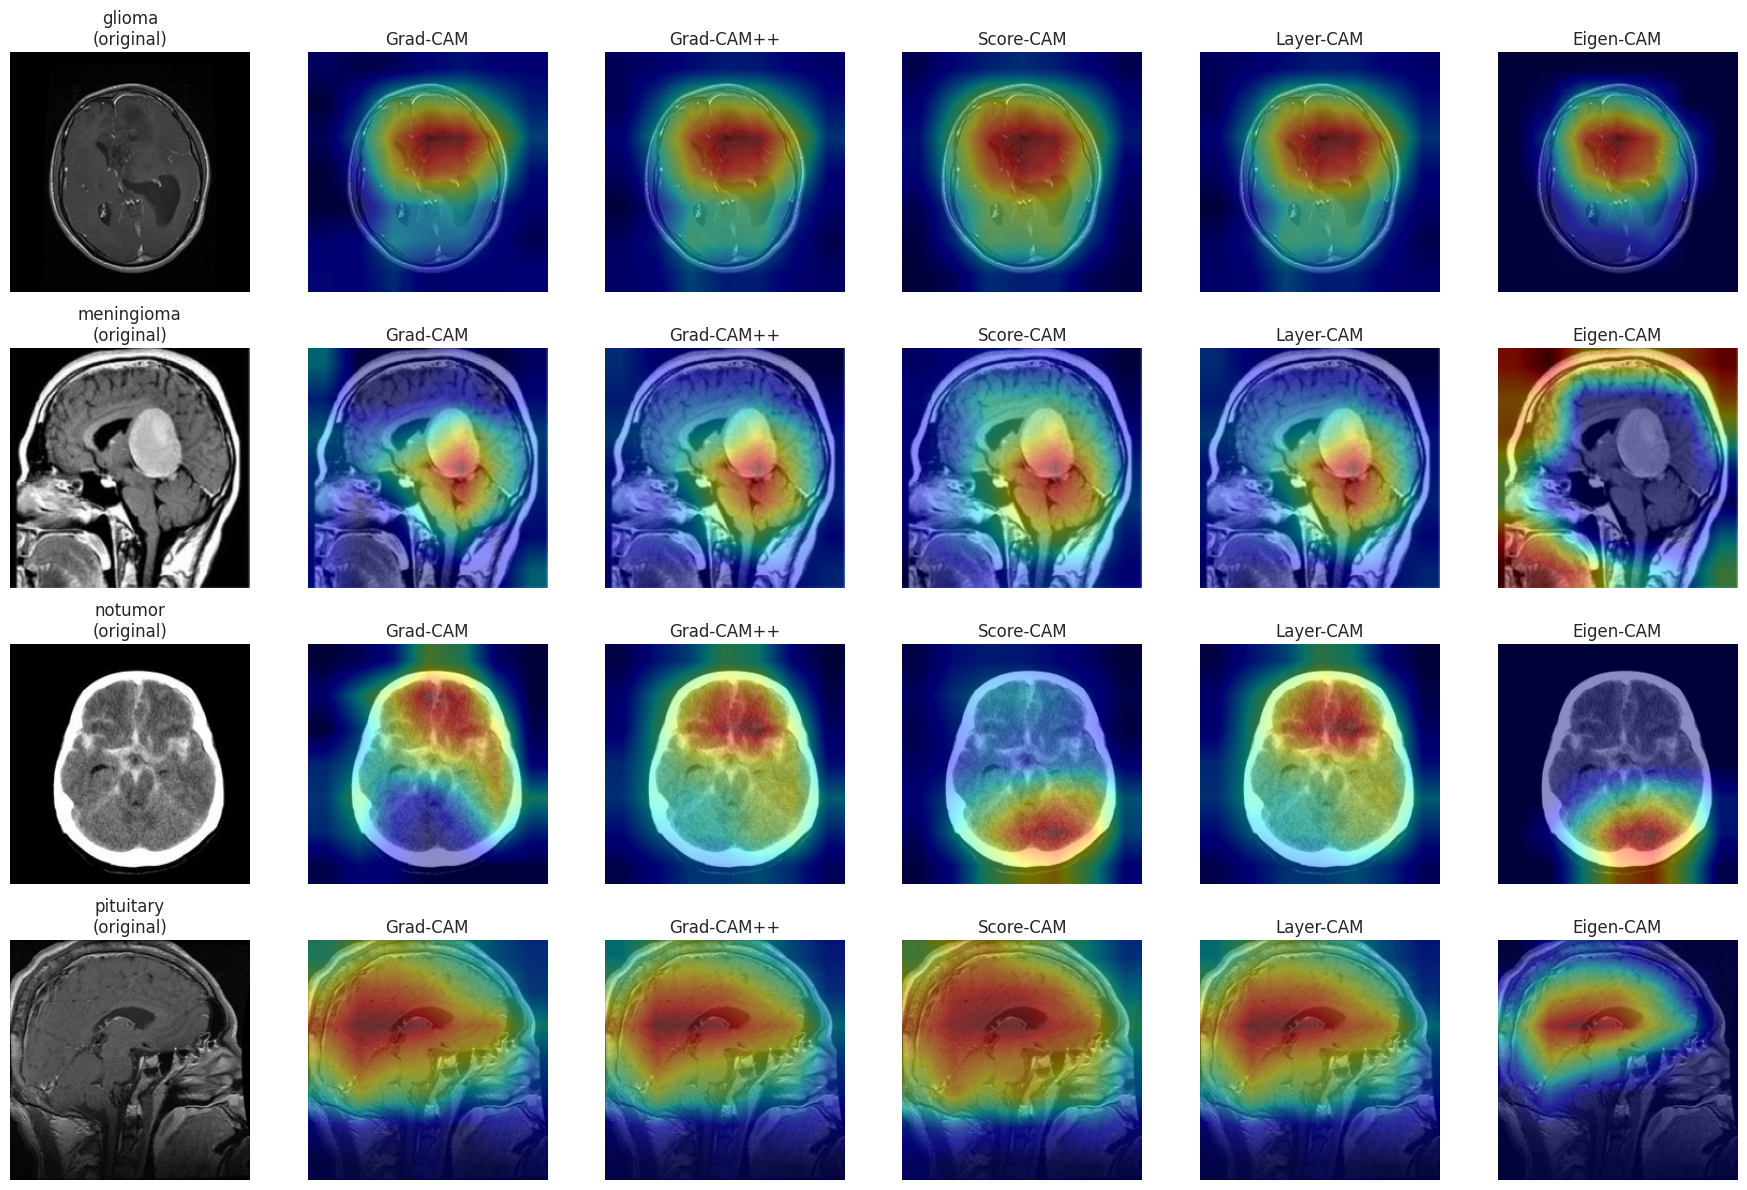

In [84]:
labels_shown = [c for c in CLASS_NAMES if c in example_maps]
fig, axes = plt.subplots(len(labels_shown), len(CAM_METHODS) + 1, figsize=(3 * (len(CAM_METHODS) + 1), 3 * len(labels_shown)))
axes = np.atleast_2d(axes)
for r, label in enumerate(labels_shown):
    image = example_maps[label]["image"]
    axes[r, 0].imshow(image)
    axes[r, 0].set_title(f"{label}\n(original)")
    for c, method in enumerate(CAM_METHODS, start=1):
        axes[r, c].imshow(image)
        axes[r, c].imshow(example_maps[label]["maps"][method], cmap="jet", alpha=0.45)
        axes[r, c].set_title(method)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "cam_examples.png"), dpi=120)
plt.show()

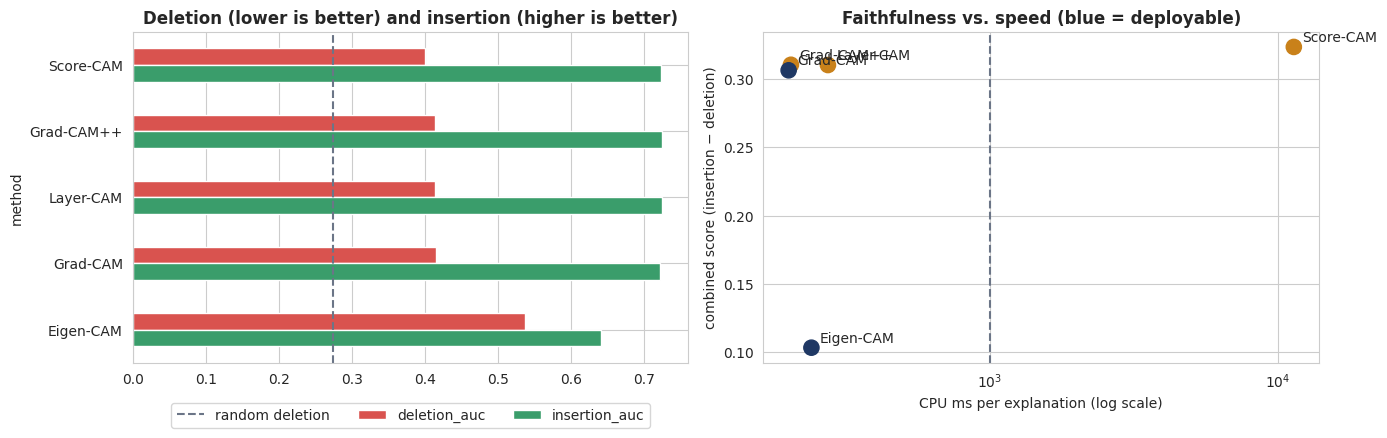

In [85]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
cam_table[["deletion_auc", "insertion_auc"]].plot(kind="barh", ax=axes[0], color=["#d9534f", "#3a9d6b"])
axes[0].axvline(cam_table["random_deletion_auc"].iloc[0], color="#6b7587", linestyle="--", label="random deletion")
axes[0].set_title("Deletion (lower is better) and insertion (higher is better)", fontweight="bold")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
axes[0].invert_yaxis()

colors = ["#1f3864" if d else "#c9811a" for d in cam_table["deployable"]]
axes[1].scatter(cam_table["cpu_ms"], cam_table["combined_score"], s=120, color=colors)
for method, r in cam_table.iterrows():
    axes[1].annotate(method, (r["cpu_ms"], r["combined_score"]), xytext=(6, 4), textcoords="offset points")
axes[1].axvline(CPU_TIME_LIMIT_MS, color="#6b7587", linestyle="--")
axes[1].set_xscale("log")
axes[1].set_xlabel("CPU ms per explanation (log scale)")
axes[1].set_ylabel("combined score (insertion − deletion)")
axes[1].set_title("Faithfulness vs. speed (blue = deployable)", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "cam_comparison.png"), dpi=120)
plt.show()

### 8.10 Choose the method (decision rule)

1. Keep the methods that **pass the sanity check** and explain an image in **≤ 1 s on CPU**.
2. Among those, choose the one with the highest **combined score** (insertion AUC − deletion AUC).
3. If a method that was excluded only because of its speed has a higher score, report it as an **offline, high-fidelity option**.

The chosen method is written to `model_info.json` next to the exported model, so the backend and dashboard know which explanation to use.

In [86]:
deployable = cam_table[cam_table["deployable"]]
if deployable.empty:
    # Nothing met the CPU limit on this machine: fall back to the methods that at least pass the sanity check
    print(f"Note: no method passed the sanity check within {CPU_TIME_LIMIT_MS} ms; choosing among those that pass the sanity check.")
    deployable = cam_table[cam_table["sanity_pass"]]
if deployable.empty:
    raise RuntimeError("No method passed the sanity check — check the model and cam_table before deploying.")
chosen = deployable["combined_score"].idxmax()
best_overall = cam_table["combined_score"].idxmax()

r = cam_table.loc[chosen]
print(f"CHOSEN: {chosen}")
print(f"  deletion AUC {r['deletion_auc']:.3f} (random {r['random_deletion_auc']:.3f}) | insertion AUC {r['insertion_auc']:.3f} | "
      f"faithful cases {r['faithful_case_rate'] * 100:.0f}% | sanity correlation {r['sanity_correlation']:.2f} | {r['cpu_ms']:.0f} ms on CPU")
if best_overall != chosen:
    b = cam_table.loc[best_overall]
    reason = "failed the sanity check" if not b["sanity_pass"] else f"takes {b['cpu_ms']:.0f} ms on CPU"
    print(f"  {best_overall} scored higher ({b['combined_score']:.3f} vs {r['combined_score']:.3f}) but {reason} — offline option only.")
failed_sanity = cam_table.index[~cam_table["sanity_pass"]].tolist()
if failed_sanity:
    print("  Failed the sanity check (maps barely depend on the trained weights):", ", ".join(failed_sanity))

info_path = os.path.join(OUTPUT_DIR, "selected", "model_info.json")
selected_info.update({
    "explanation_method": chosen,
    "explanation_layer": CAM_LAYER,
    "explanation_metrics": {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else bool(v))
                            for k, v in cam_table.loc[chosen].items()},
})
with open(info_path, "w") as f:
    json.dump(selected_info, f, indent=2)
print("\nSaved to", info_path)

CHOSEN: Grad-CAM
  deletion AUC 0.415 (random 0.274) | insertion AUC 0.722 | faithful cases 25% | sanity correlation 0.23 | 200 ms on CPU
  Score-CAM scored higher (0.323 vs 0.306) but failed the sanity check — offline option only.
  Failed the sanity check (maps barely depend on the trained weights): Score-CAM, Grad-CAM++, Layer-CAM

Saved to /content/drive/MyDrive/NeuroLens/selected/model_info.json


## 9. Similar-case search — does the case evidence help?

For every prediction, the dashboard also shows the **most similar confirmed cases** and how many of them share the predicted class ("4 of 5 similar cases are glioma"). That evidence is only useful if it is trustworthy, so this section tests it offline, with exactly the setup the application uses:

- **Reference library** = the training images (the application loads training images into its library; the test images are never used for that).
- **Queries** = the test images.
- **Embedding** = the input of the selected model's final Dense layer, scaled to unit length — the same vector the backend stores for every scan.

| Question | Measure |
|---|---|
| Are the nearest cases of the right class? | **Precision@k** (k = 1, 5, 10): share of the k nearest reference cases with the query's true class |
| Could the neighbours alone classify the image? | **kNN accuracy**: majority vote of the k nearest cases, compared with the classifier's own accuracy |
| Does disagreement warn about mistakes? | **Error-detection AUROC**: how well a low agreement ("2 of 5") separates the model's wrong predictions from its correct ones (0.5 = no better than chance) |
| Are the similarity percentages meaningful? | Similarity distribution of same-class vs. different-class pairs |

**Baselines** — to show that the model's own features are the right thing to compare:

| Features | Why it is a baseline |
|---|---|
| Raw pixels (32 × 32 grayscale) | "Do the images simply look alike?" — no learning at all |
| Generic ImageNet features (MobileNetV2, not fine-tuned) | Features from a model that has never seen an MRI |
| **Selected model's features** (cosine) | what the application uses |
| Selected model's features (Euclidean, not normalised) | the other common distance |

**Decision rule** (fixed in advance): the application keeps the selected model's features with cosine similarity if they give the highest precision@5; `k` for the dashboard is the value (3, 5, 7 or 10) with the best error-detection AUROC.

*If this runs in a new Colab session: run Sections 1–4 first, and the Fibonacci-Net custom-layer cell (Section 6.3, Step 1) if the selected model is Fibonacci-Net.*

### 9.1 Settings and the selected model

In [87]:
from sklearn.metrics import roc_auc_score

K_VALUES = [1, 5, 10]              # precision@k
K_CANDIDATES = [3, 5, 7, 10]       # candidates for the k shown in the dashboard
RETRIEVAL_BATCH = 64

retrieval_model = tf.keras.models.load_model(os.path.join(OUTPUT_DIR, "selected", "brain_tumor_model.keras"), compile=False)
with open(os.path.join(OUTPUT_DIR, "selected", "model_info.json")) as f:
    selected_info = json.load(f)
print("Selected model:", selected_info["model"], selected_info["config"])
print(f"Reference library (training split): {len(train_df)} images | queries (test split): {len(test_df)} images")

Selected model: Fibonacci-Net lr=0.0003
Reference library (training split): 4625 images | queries (test split): 1311 images


### 9.2 Feature extractors

Each extractor turns a batch of images (pixels 0–1, as in the generators) into one vector per image.

- `model_features` is the backend's embedding: a second output at the **input of the final Dense layer**.
- `imagenet_features` uses MobileNetV2 with ImageNet weights and no fine-tuning (global average pooling, 1,280 values).
- `pixel_features` shrinks the image to 32 × 32 grayscale (1,024 values).

In [88]:
head = next(layer for layer in reversed(retrieval_model.layers) if isinstance(layer, tf.keras.layers.Dense))
feature_model = tf.keras.Model(retrieval_model.inputs, [head.input, retrieval_model.output])
print(f"Embedding: input of '{head.name}' — {int(head.input.shape[-1])} values per image")

imagenet_backbone = tf.keras.applications.MobileNetV2(include_top=False, weights="imagenet", pooling="avg",
                                                      input_shape=IMG_SIZE + (3,))
imagenet_model = tf.keras.Sequential([tf.keras.layers.Rescaling(2.0, offset=-1.0), imagenet_backbone])   # 0-1 -> -1..1


def pixel_features(batch):
    grey = tf.image.rgb_to_grayscale(tf.image.resize(batch, (32, 32), method="area"))
    return grey.numpy().reshape(len(batch), -1)


def extract(df, name):
    """Runs every image of df through the three extractors once (same order as df)."""
    gen = ImageDataGenerator(rescale=1.0 / 255).flow_from_dataframe(
        df, x_col="image_path", y_col="label", classes=CLASS_NAMES, target_size=IMG_SIZE,
        class_mode="categorical", batch_size=RETRIEVAL_BATCH, shuffle=False)
    out = {"model": [], "probs": [], "imagenet": [], "pixels": []}
    for _ in range(len(gen)):
        x, _ = next(gen)
        emb, probs = feature_model.predict(x, verbose=0)
        out["model"].append(emb)
        out["probs"].append(probs)
        out["imagenet"].append(imagenet_model.predict(x, verbose=0))
        out["pixels"].append(pixel_features(x))
    out = {k: np.concatenate(v) for k, v in out.items()}
    out["labels"] = np.asarray(gen.classes)
    print(f"{name}: {len(out['labels'])} images, embedding {out['model'].shape[1]} values")
    return out


start = time.time()
reference = extract(train_df, "Reference library")
queries = extract(test_df, "Queries")
print(f"Features extracted in {(time.time() - start) / 60:.1f} min")

Embedding: input of 'dense_8' — 377 values per image
Found 4625 validated image filenames belonging to 4 classes.
Reference library: 4625 images, embedding 377 values
Found 1311 validated image filenames belonging to 4 classes.
Queries: 1311 images, embedding 377 values
Features extracted in 1.4 min


### 9.3 Nearest neighbours and the retrieval metrics

`nearest(...)` returns, for every query, the indices of the reference cases ordered from most to least similar (cosine: highest dot product of unit vectors; Euclidean: smallest distance).

In [89]:
def unit(v):
    return v / np.maximum(np.linalg.norm(v, axis=1, keepdims=True), 1e-12)


def nearest(query_vectors, reference_vectors, metric, k):
    """Indices (queries x k) of the k most similar reference cases, and their cosine similarity or distance."""
    if metric == "cosine":
        scores = unit(query_vectors) @ unit(reference_vectors).T
        order = np.argsort(-scores, axis=1)[:, :k]
    else:
        q2 = (query_vectors ** 2).sum(axis=1)[:, None]
        r2 = (reference_vectors ** 2).sum(axis=1)[None, :]
        scores = np.sqrt(np.maximum(q2 + r2 - 2 * query_vectors @ reference_vectors.T, 0))
        order = np.argsort(scores, axis=1)[:, :k]
    return order, np.take_along_axis(scores, order, axis=1)


def knn_vote(neighbour_labels, k):
    """Majority class of the k nearest cases; ties go to the class of the nearest case among the tied classes."""
    votes = []
    for row in neighbour_labels[:, :k]:
        counts = np.bincount(row, minlength=len(CLASS_NAMES))
        tied = np.flatnonzero(counts == counts.max())
        votes.append(next(label for label in row if label in tied))
    return np.asarray(votes)


def error_detection_auroc(agreement, correct):
    """AUROC of (1 - agreement) for flagging wrong predictions; NaN if the model made no mistakes."""
    wrong = ~correct
    if wrong.all() or not wrong.any():
        return float("nan")
    return float(roc_auc_score(wrong, 1 - agreement))


model_pred = queries["probs"].argmax(axis=1)
model_correct = model_pred == queries["labels"]
print(f"Classifier accuracy on the queries: {model_correct.mean():.3f} ({(~model_correct).sum()} wrong predictions)")

Classifier accuracy on the queries: 0.958 (55 wrong predictions)


### 9.4 Compare the feature types

For every feature type: precision@1/5/10, kNN accuracy (k = 5), and how well the agreement between the **classifier's prediction** and the 5 nearest cases flags the classifier's mistakes.

In [90]:
FEATURES = [
    ("Raw pixels (32x32)", "pixels", "cosine"),
    ("ImageNet MobileNetV2 (not fine-tuned)", "imagenet", "cosine"),
    ("Selected model — cosine (used by the app)", "model", "cosine"),
    ("Selected model — Euclidean", "model", "euclidean"),
]
max_k = max(K_VALUES + K_CANDIDATES)
rows, neighbours = [], {}
for name, key, metric in FEATURES:
    order, scores = nearest(queries[key], reference[key], metric, max_k)
    neighbour_labels = reference["labels"][order]
    neighbours[name] = (order, scores, neighbour_labels)
    row = {"features": name, "metric": metric, "dimensions": queries[key].shape[1]}
    for k in K_VALUES:
        row[f"precision@{k}"] = float((neighbour_labels[:, :k] == queries["labels"][:, None]).mean())
    row["knn_accuracy@5"] = float((knn_vote(neighbour_labels, 5) == queries["labels"]).mean())
    agreement = (neighbour_labels[:, :5] == model_pred[:, None]).mean(axis=1)
    row["error_detection_auroc@5"] = error_detection_auroc(agreement, model_correct)
    rows.append(row)

retrieval_table = pd.DataFrame(rows).set_index("features")
retrieval_table.loc["Classifier (for reference)", "knn_accuracy@5"] = float(model_correct.mean())
retrieval_table.to_csv(os.path.join(OUTPUT_DIR, "retrieval_comparison.csv"))
retrieval_table.round(3)

,metric,dimensions,precision@1,precision@5,precision@10,knn_accuracy@5,error_detection_auroc@5
features,,,,,,,
Raw pixels (32x32),cosine,1024.0,0.946,0.799,0.741,0.834,0.849
ImageNet MobileNetV2 (not fine-tuned),cosine,1280.0,0.952,0.862,0.822,0.900,0.842
Selected model — cosine (used by the app),cosine,377.0,0.975,0.954,0.945,0.963,0.861
Selected model — Euclidean,euclidean,377.0,0.972,0.952,0.944,0.963,0.860
Classifier (for reference),NaN,NaN,NaN,NaN,NaN,0.958,NaN


### 9.5 Choosing k for the dashboard

The dashboard shows *k* similar cases and their agreement. More cases give a steadier vote but include less similar ones. Using the application's features (selected model, cosine), each candidate k is scored on kNN accuracy and on how well a low agreement flags the classifier's mistakes.

In [91]:
app_name = "Selected model — cosine (used by the app)"
_, app_scores, app_labels = neighbours[app_name]
k_rows = []
for k in K_CANDIDATES:
    agreement = (app_labels[:, :k] == model_pred[:, None]).mean(axis=1)
    k_rows.append({
        "k": k,
        "knn_accuracy": float((knn_vote(app_labels, k) == queries["labels"]).mean()),
        "error_detection_auroc": error_detection_auroc(agreement, model_correct),
        "mean_agreement_when_correct": float(agreement[model_correct].mean()),
        "mean_agreement_when_wrong": float(agreement[~model_correct].mean()) if (~model_correct).any() else float("nan"),
    })
k_table = pd.DataFrame(k_rows).set_index("k")
k_table.round(3)

,knn_accuracy,error_detection_auroc,mean_agreement_when_correct,mean_agreement_when_wrong
k,,,,
3,0.966,0.868,0.986,0.582
5,0.963,0.861,0.982,0.651
7,0.962,0.853,0.977,0.686
10,0.961,0.844,0.975,0.724


In [92]:
if k_table["error_detection_auroc"].notna().any():
    best_k = int(k_table["error_detection_auroc"].idxmax())
    reason = "best error-detection AUROC"
else:
    best_k = int(k_table["knn_accuracy"].idxmax())
    reason = "best kNN accuracy (the model made no mistakes on the test set, so AUROC is undefined)"
print(f"Recommended k for the dashboard: {best_k} ({reason})")

# How the classifier's accuracy depends on the case agreement at that k
agreement = (app_labels[:, :best_k] == model_pred[:, None]).mean(axis=1)
bands = pd.cut(agreement, bins=[-0.01, 0.5, 0.79, 1.0], labels=["half or fewer agree", "most agree", "(nearly) all agree"])
by_band = pd.DataFrame({"agreement": bands, "correct": model_correct}).groupby("agreement", observed=False)["correct"]
pd.DataFrame({"scans": by_band.size(), "share_of_scans": by_band.size() / len(agreement), "classifier_accuracy": by_band.mean()}).round(3)

Recommended k for the dashboard: 3 (best error-detection AUROC)


,scans,share_of_scans,classifier_accuracy
agreement,,,
half or fewer agree,29,0.022,0.310
most agree,56,0.043,0.607
(nearly) all agree,1226,0.935,0.989


**Reading the table above:** if the classifier is clearly less accurate when few similar cases agree, the dashboard's case agreement is a useful warning — those scans deserve a closer look. This is the evidence for showing similar cases next to the prediction.

### 9.6 Are the similarity percentages meaningful?

The dashboard shows cosine similarity as a percentage. For a query, compare the similarity of its nearest **same-class** case with that of its nearest **different-class** case. If the two distributions overlap heavily, the percentages look similar for everything and should be read as a ranking rather than as an absolute score.

Nearest same-class case:      mean similarity 98.6%
Nearest different-class case: mean similarity 89.0%
Random pair:                  mean similarity 55.9%
Separation AUROC (same vs. different class): 0.980


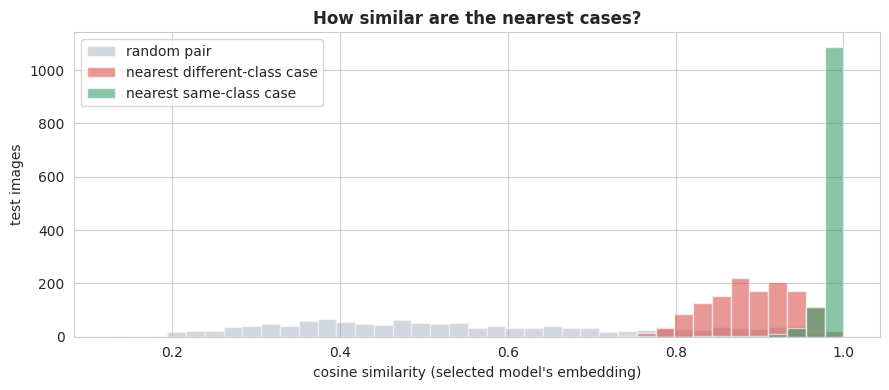

In [93]:
sims = unit(queries["model"]) @ unit(reference["model"]).T
same = reference["labels"][None, :] == queries["labels"][:, None]
nearest_same = np.where(same, sims, -np.inf).max(axis=1)
nearest_other = np.where(~same, sims, -np.inf).max(axis=1)
random_pairs = sims[np.arange(len(sims)), np.random.default_rng(SEED).integers(0, sims.shape[1], len(sims))]

separation = float(roc_auc_score(np.r_[np.ones_like(nearest_same), np.zeros_like(nearest_other)], np.r_[nearest_same, nearest_other]))
print(f"Nearest same-class case:      mean similarity {nearest_same.mean() * 100:.1f}%")
print(f"Nearest different-class case: mean similarity {nearest_other.mean() * 100:.1f}%")
print(f"Random pair:                  mean similarity {random_pairs.mean() * 100:.1f}%")
print(f"Separation AUROC (same vs. different class): {separation:.3f}")

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(min(nearest_other.min(), random_pairs.min()), 1, 40)
ax.hist(random_pairs, bins=bins, alpha=0.45, color="#9aa5b8", label="random pair")
ax.hist(nearest_other, bins=bins, alpha=0.6, color="#d9534f", label="nearest different-class case")
ax.hist(nearest_same, bins=bins, alpha=0.6, color="#3a9d6b", label="nearest same-class case")
ax.set_xlabel("cosine similarity (selected model's embedding)")
ax.set_ylabel("test images")
ax.set_title("How similar are the nearest cases?", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "retrieval_similarity.png"), dpi=120)
plt.show()

### 9.7 Examples

One test image per class with its nearest reference cases (application features). Green title = same class as the query.

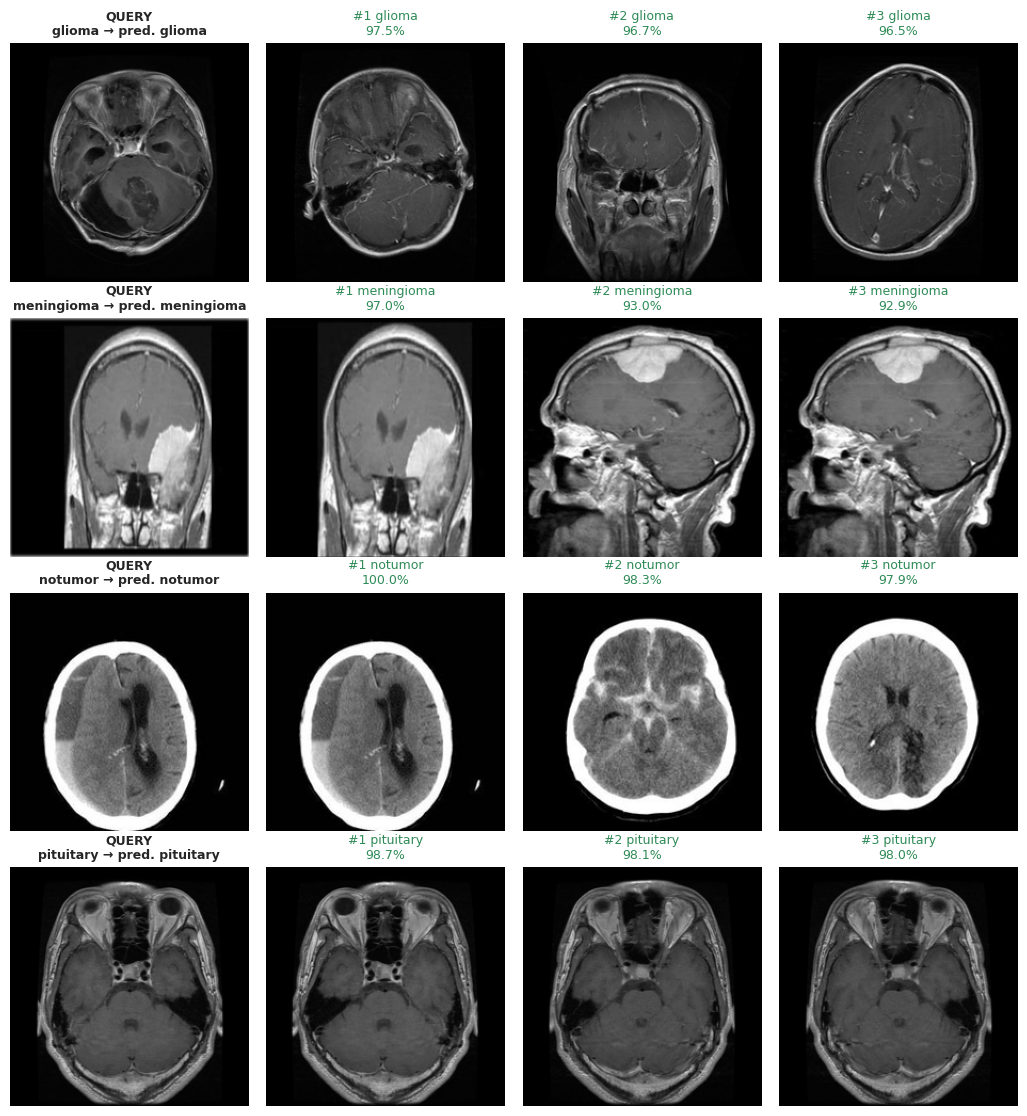

In [94]:
examples = [np.flatnonzero(queries["labels"] == c)[0] for c in range(len(CLASS_NAMES)) if (queries["labels"] == c).any()]
order, scores, _ = neighbours[app_name]
n_show = min(best_k, 5)
fig, axes = plt.subplots(len(examples), n_show + 1, figsize=(2.6 * (n_show + 1), 2.8 * len(examples)))
axes = np.atleast_2d(axes)
for r, q in enumerate(examples):
    axes[r, 0].imshow(Image.open(test_df["image_path"].iloc[q]).convert("RGB").resize(IMG_SIZE))
    axes[r, 0].set_title(f"QUERY\n{CLASS_NAMES[queries['labels'][q]]} → pred. {CLASS_NAMES[model_pred[q]]}", fontsize=9, fontweight="bold")
    for c in range(n_show):
        ref = order[q, c]
        label = CLASS_NAMES[reference["labels"][ref]]
        axes[r, c + 1].imshow(Image.open(train_df["image_path"].iloc[ref]).convert("RGB").resize(IMG_SIZE))
        axes[r, c + 1].set_title(f"#{c + 1} {label}\n{scores[q, c] * 100:.1f}%", fontsize=9,
                                 color="#2e8b57" if reference["labels"][ref] == queries["labels"][q] else "#c8453f")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "retrieval_examples.png"), dpi=120)
plt.show()

### 9.8 Decision and record

The chosen settings are added to `model_info.json` next to the exported model, together with the numbers for the report.

In [95]:
best_features = retrieval_table.drop(index="Classifier (for reference)")["precision@5"].idxmax()
app_row = retrieval_table.loc[app_name]
print(f"Highest precision@5: {best_features}")
if best_features == app_name:
    print("-> The application's choice (selected model's embedding, cosine similarity) is confirmed.")
else:
    print(f"-> Note: '{best_features}' retrieved better than the application's features — discuss this in the report.")
print(f"Application features: precision@5 {app_row['precision@5']:.3f} | kNN accuracy {app_row['knn_accuracy@5']:.3f} | "
      f"error-detection AUROC {app_row['error_detection_auroc@5']:.3f} | recommended k = {best_k}")

info_path = os.path.join(OUTPUT_DIR, "selected", "model_info.json")
with open(info_path) as f:
    selected_info = json.load(f)                      # re-read: Section 8 may have added the explanation method
selected_info["similar_cases"] = {
    "embedding": f"input of the final Dense layer '{head.name}', unit length",
    "embedding_dimensions": int(head.input.shape[-1]),
    "similarity": "cosine",
    "recommended_k": best_k,
    "precision_at_5": round(float(app_row["precision@5"]), 4),
    "knn_accuracy_at_5": round(float(app_row["knn_accuracy@5"]), 4),
    "error_detection_auroc_at_5": None if np.isnan(app_row["error_detection_auroc@5"]) else round(float(app_row["error_detection_auroc@5"]), 4),
    "same_vs_different_class_separation_auroc": round(separation, 4),
    "reference_library": "training split",
}
with open(info_path, "w") as f:
    json.dump(selected_info, f, indent=2)
print("Saved to", info_path)

Highest precision@5: Selected model — cosine (used by the app)
-> The application's choice (selected model's embedding, cosine similarity) is confirmed.
Application features: precision@5 0.954 | kNN accuracy 0.963 | error-detection AUROC 0.861 | recommended k = 3
Saved to /content/drive/MyDrive/NeuroLens/selected/model_info.json


## 10. Publish the selected model for the NeuroLens application

The application downloads its model from the **Hugging Face Hub** when it starts, so switching it to the brain tumor model needs no code change — only the model upload and a few settings.

What happens here:
1. Check the exported files.
2. Upload `brain_tumor_model.keras`, `model_info.json` and a short model card to a Hugging Face model repository.
3. Print the exact settings for the Azure Web App and for a local `backend/.env`.

**Before running:** create a Hugging Face **access token with write permission** (huggingface.co → Settings → Access tokens) and add it to Colab's **Secrets** (key icon in the left sidebar) as `HF_TOKEN`, with notebook access switched on. The token is read from the secret and never printed or saved in the notebook.

### 10.1 Check the exported files

In [96]:
PUBLISH_DIR = os.path.join(OUTPUT_DIR, "selected")
MODEL_FILE = "brain_tumor_model.keras"
with open(os.path.join(PUBLISH_DIR, "model_info.json")) as f:
    publish_info = json.load(f)

# The application needs the class names in the model's output order
assert publish_info["class_names"] == CLASS_NAMES, "class order differs from the training generators"
check = tf.keras.models.load_model(os.path.join(PUBLISH_DIR, MODEL_FILE), compile=False)
assert int(check.output_shape[-1]) == len(CLASS_NAMES), "the model's outputs do not match the classes"

print("Model:              ", publish_info["model"], "·", publish_info["config"])
print("Classes (in order): ", ", ".join(publish_info["class_names"]))
print("Explanation method: ", publish_info.get("explanation_method", "not chosen yet — run Section 8"))
print("Similar cases (k):  ", publish_info.get("similar_cases", {}).get("recommended_k", "not chosen yet — run Section 9"))
print("File size:          ", f"{os.path.getsize(os.path.join(PUBLISH_DIR, MODEL_FILE)) / 1e6:.1f} MB")

Model:               Fibonacci-Net · lr=0.0003
Classes (in order):  glioma, meningioma, notumor, pituitary
Explanation method:  Grad-CAM
Similar cases (k):   3
File size:           4.8 MB


### 10.2 Upload to Hugging Face

Set `HF_REPO_ID` to your repository (`<your-username>/<repository-name>`). The repository is created if it does not exist. Keep `HF_PRIVATE = False` unless you also give the application a read token (`HF_TOKEN` setting).

In [98]:
HF_REPO_ID = "Bharathikannan/brain-tumor-classification"     # <- your Hugging Face username / repository name
HF_PRIVATE = False

from huggingface_hub import HfApi
try:
    from google.colab import userdata
    hf_token = userdata.get("HF_TOKEN")
except Exception:
    hf_token = os.environ.get("HF_TOKEN")
if not hf_token:
    raise RuntimeError("Add a write token as the Colab secret HF_TOKEN (see the note above).")

metrics = {k.replace("test_", ""): publish_info[k] for k in ("test_accuracy", "test_macro_f1") if k in publish_info}
card = f"""---
tags: [keras, image-classification, medical-imaging, brain-tumor-mri]
---
# NeuroLens — brain tumor MRI classifier

Selected model of the NeuroLens project (NUS-ISS PRS Practice Module): **{publish_info['model']}** ({publish_info['config']}).

- Classes (output order): {', '.join(publish_info['class_names'])}
- Input: {IMG_SIZE[0]} x {IMG_SIZE[1]} RGB, pixels / 255
- Explanation method: {publish_info.get('explanation_method', 'Grad-CAM')}
- Test metrics: {', '.join(f'{k} {v:.3f}' for k, v in metrics.items() if isinstance(v, (int, float))) or 'see model_info.json'}
- Training data: Kaggle Brain Tumor MRI dataset (masoudnickparvar, version 1)

Research prototype — **not a diagnostic device**. Full details in `model_info.json`.
"""
with open(os.path.join(PUBLISH_DIR, "README.md"), "w") as f:
    f.write(card)

api = HfApi(token=hf_token)
api.create_repo(HF_REPO_ID, repo_type="model", private=HF_PRIVATE, exist_ok=True)
commit = api.upload_folder(repo_id=HF_REPO_ID, folder_path=PUBLISH_DIR, allow_patterns=[MODEL_FILE, "model_info.json", "README.md"],
                           commit_message=f"Upload {publish_info['model']} ({publish_info['config']})")
print("Uploaded:", f"https://huggingface.co/{HF_REPO_ID}")
print("Revision:", commit.oid[:7])

Uploaded: https://huggingface.co/Bharathikannan/brain-tumor-classification
Revision: 3f681b4


### 10.3 Settings for the application

Copy the printed settings:
- **Azure** — run the `az` command in a terminal where the Azure CLI is logged in (or paste the values in Azure Portal → App Services → `neurolens-xai` → Environment variables). The web app restarts and downloads the new model.
- **Local** — replace the matching lines in `backend/.env` and restart `python app.py`.

Then load the reference library for similar-case search (next step).

In [99]:
display_name = f"{publish_info['model']} ({publish_info['config']})"
settings = {
    "HF_REPO_ID": HF_REPO_ID,
    "HF_MODEL_FILENAME": MODEL_FILE,
    "CLASS_NAMES": ",".join(publish_info["class_names"]),
    "MODEL_DISPLAY_NAME": display_name,
    "SIMILAR_K": str(publish_info.get("similar_cases", {}).get("recommended_k", 5)),
}
print("Azure (one command):\n")
print("az webapp config appsettings set -g mlprojectdocker -n neurolens-xai --settings " +
      " ".join(f'"{k}={v}"' for k, v in settings.items()))
print("\nLocal backend/.env:\n")
print("\n".join(f"{k}={v}" for k, v in settings.items()))

method = publish_info.get("explanation_method", "Grad-CAM")
if method != "Grad-CAM":
    print(f"\nNote: Section 8 chose {method}. The application currently draws Grad-CAM heatmaps — "
          "add the chosen method to backend/utils/gradcam.py before relying on it in the dashboard.")

Azure (one command):

az webapp config appsettings set -g mlprojectdocker -n neurolens-xai --settings "HF_REPO_ID=Bharathikannan/brain-tumor-classification" "HF_MODEL_FILENAME=brain_tumor_model.keras" "CLASS_NAMES=glioma,meningioma,notumor,pituitary" "MODEL_DISPLAY_NAME=Fibonacci-Net (lr=0.0003)" "SIMILAR_K=3"

Local backend/.env:

HF_REPO_ID=Bharathikannan/brain-tumor-classification
HF_MODEL_FILENAME=brain_tumor_model.keras
CLASS_NAMES=glioma,meningioma,notumor,pituitary
MODEL_DISPLAY_NAME=Fibonacci-Net (lr=0.0003)
SIMILAR_K=3


### 10.4 Load the reference library (on your computer)

Similar-case search needs confirmed cases. Load the **training** images — never the test images — with the backend's script, from the `backend/` folder with its virtual environment active and `backend/.env` already switched to the new model (Step 10.3):

```bash
python -c "import kagglehub; print(kagglehub.dataset_download('masoudnickparvar/brain-tumor-mri-dataset/versions/1'))"
python scripts/load_reference_library.py --data-dir "<printed folder>/Training" --per-class 250 --source "Kaggle Brain Tumor MRI v1 (training split)"
```

The script classifies each image with the published model, stores the image and heatmap in Azure Blob Storage, and adds the embedding to MongoDB (`reference_cases`). `--per-class 250` gives 1,000 reference cases; use `--per-class 0` for the whole training split.

**Final check** — open the live dashboard, classify a test image, and confirm that **Model & System** shows the new model, and **Find similar cases** returns reference cases.